# Biology-informed RNNs vs mixed-effects models for hippocampal atrophy forecasting (ADNI-1, n = 382)

This notebook produces **every number, table and figure** reported for this study.

| Design element | Implementation |
|---|---|
| Evaluation | 5-fold subject-level cross-validation stratified by diagnosis, repeated 3× → out-of-fold forecasts for all 382 subjects |
| Model selection | Inner validation split (15 % of training subjects) for early stopping. Hyper-parameters are fixed a priori, and nothing is tuned on test subjects |
| Baselines | Persistence, population drift, per-subject linear extrapolation, ARIMA, linear mixed-effects models (with/without clinical covariates), XGBoost (with/without covariates) |
| Sequence-only RNNs | GRU / LSTM / Bi-LSTM trained with MSE or with the biological-corridor loss. Comparators: post-hoc clipping and a hard-constrained output layer |
| Proposed hybrid | Mixed-effects (BLUP) forecast + biology-informed RNN correction (cross-fitted prior, 5-member deep ensemble) |
| Uncertainty | Analytic mixed-effects prediction intervals and split-conformal intervals |
| Statistics | Subject-level bootstrap 95 % CIs, paired Wilcoxon tests with Holm correction, TOST equivalence tests |
| Robustness | Loss-component and hybrid ablations, λ/τ sensitivity, absolute-output (non-anchored) protocol, all-visit forecasting |

**Run:** `Kernel → Restart & Run All` (about 20 min on an 8-core laptop CPU, no GPU needed). Trained models are cached in `results/predictions/`.
Figures are saved to `results/figures/` as PNG and PDF, and the main figures also as 300-dpi TIFFs (`results/figures/plos/`).
Tables are saved to `results/tables/`.

In [1]:
import os, sys, json, time, math, random, warnings, platform, pickle
from pathlib import Path

import numpy as np
import pandas as pd
# NOTE: xgboost must be imported BEFORE torch on macOS, otherwise the two OpenMP runtimes clash and the kernel segfaults
import xgboost
from xgboost import XGBRegressor
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.model_selection import StratifiedKFold, train_test_split
from scipy import stats
import statsmodels
import statsmodels.formula.api as smf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.weightstats import ttost_paired
from patsy import build_design_matrices
from joblib import Parallel, delayed
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220, 'display.max_columns', 40)

QUICK = os.environ.get('BIRNN_QUICK', '0') == '1'   # True -> fast smoke test with tiny settings
FORCE_RERUN = False                                  # True -> ignore cached training results

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data'
VOL_CSV = DATA_DIR / 'hippocampal_volumes_382.csv'                     # FastSurfer bilateral hippocampal volumes
META_CSV = DATA_DIR / 'ADNI1_Complete_3Yr_1.5T_10_02_2025.csv'         # ADNI collection metadata (scan dates, age, sex)
OUT = ROOT / ('results_quick' if QUICK else 'results')
FIG, TAB, PRED = OUT / 'figures', OUT / 'tables', OUT / 'predictions'
PLOSFIG = FIG / 'plos'
for p in (FIG, TAB, PRED, PLOSFIG):
    p.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=2026,
    n_folds=5, n_repeats=3, inner_val_frac=0.15,
    # sequence-only RNNs (identical for standard and biology-informed variants)
    hidden=64, lr=1e-3, batch_size=32, max_epochs=300, patience=30, grad_clip=1.0,
    # biological corridor
    lam_traj=1.0, lam_bio=2.0, lam_smooth=1.0,
    tau_noise=0.01,          # growth above 1 % of the last volume = biologically implausible
    tau_drop_visit=0.05,     # fixed cap: at most 5 % loss per visit (non-anchored protocol)
    tau_drop_annual=0.10,    # time-scaled cap: 10 %/year x interval
    # absolute-output protocol (Part A)
    paper_epochs=100, paper_batch_size=1,
    # hybrid model
    hyb_ensemble=5, hyb_weight_decay=1e-4, hyb_crossfit_k=5,
    lme_formula_base='y ~ t', lme_formula_cov='y ~ t * dx + age_c + male + age_c:t',
    # statistics
    n_boot=2000, alpha=0.05, equivalence_margin=5.0,   # mm3, pre-specified TOST margin
    n_jobs=max(1, min(8, (os.cpu_count() or 2) - 1)),
)
if QUICK:
    CFG.update(n_folds=3, n_repeats=1, max_epochs=12, patience=4, paper_epochs=2, n_boot=200, hyb_ensemble=2, hyb_crossfit_k=3)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(CFG['seed'])
ENV = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
       'torch': torch.__version__, 'statsmodels': statsmodels.__version__, 'xgboost': xgboost.__version__,
       'platform': platform.platform(), 'quick_mode': QUICK}
print(json.dumps(ENV, indent=1)); print(json.dumps(CFG, indent=1))

{
 "python": "3.12.7",
 "numpy": "1.26.4",
 "pandas": "2.2.2",
 "torch": "2.9.1",
 "statsmodels": "0.14.2",
 "xgboost": "3.2.0",
 "platform": "macOS-26.6.2-arm64-arm-64bit",
 "quick_mode": false
}
{
 "seed": 2026,
 "n_folds": 5,
 "n_repeats": 3,
 "inner_val_frac": 0.15,
 "hidden": 64,
 "lr": 0.001,
 "batch_size": 32,
 "max_epochs": 300,
 "patience": 30,
 "grad_clip": 1.0,
 "lam_traj": 1.0,
 "lam_bio": 2.0,
 "lam_smooth": 1.0,
 "tau_noise": 0.01,
 "tau_drop_visit": 0.05,
 "tau_drop_annual": 0.1,
 "paper_epochs": 100,
 "paper_batch_size": 1,
 "hyb_ensemble": 5,
 "hyb_weight_decay": 0.0001,
 "hyb_crossfit_k": 5,
 "lme_formula_base": "y ~ t",
 "lme_formula_cov": "y ~ t * dx + age_c + male + age_c:t",
 "n_boot": 2000,
 "alpha": 0.05,
 "equivalence_margin": 5.0,
 "n_jobs": 7
}


In [2]:
# ---------- figure style (PLOS: width <= 7.5 in, 8-pt sans-serif, TIFF 300 dpi) ----------
sns.set_theme(style='ticks', context='paper')
matplotlib.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 120, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'figure.constrained_layout.use': True,
    'lines.linewidth': 1.2, 'axes.linewidth': 0.7})
FIG_W = 7.5

BASELINES = ['Persistence', 'Population drift', 'Linear extrapolation', 'ARIMA(1,1,0)', 'Linear mixed-effects',
             'Linear mixed-effects + covariates', 'XGBoost', 'XGBoost + covariates']
SEQ_MODELS = ['Standard GRU', 'Standard LSTM', 'Standard Bi-LSTM', 'Bio-Informed GRU', 'Bio-Informed LSTM', 'Bio-Informed Bi-LSTM',
              'Standard GRU + clip', 'Hard-corridor GRU']
HYB_MODELS = ['Hybrid GRU (no corridor)', 'Hybrid Bio-Informed LSTM', 'Hybrid Bio-Informed GRU']
PROPOSED = 'Hybrid Bio-Informed GRU'
MODEL_ORDER = BASELINES + SEQ_MODELS + HYB_MODELS
PALETTE = {'Persistence': '#9E9E9E', 'Population drift': '#BDBDBD', 'Linear extrapolation': '#BCAAA4', 'ARIMA(1,1,0)': '#D7CCC8',
           'Linear mixed-effects': '#8D6E63', 'Linear mixed-effects + covariates': '#4E342E', 'XGBoost': '#A1887F',
           'XGBoost + covariates': '#6D4C41',
           'Standard GRU': '#6BAED6', 'Standard LSTM': '#4292C6', 'Standard Bi-LSTM': '#08519C',
           'Bio-Informed GRU': '#74C476', 'Bio-Informed LSTM': '#31A354', 'Bio-Informed Bi-LSTM': '#006D2C',
           'Standard GRU + clip': '#FDAE6B', 'Hard-corridor GRU': '#E6550D',
           'Hybrid GRU (no corridor)': '#BCBDDC', 'Hybrid Bio-Informed LSTM': '#807DBA', 'Hybrid Bio-Informed GRU': '#54278F'}
DX_ORDER = ['CN', 'MCI', 'AD']
DX_COL = {'CN': '#1B9E77', 'MCI': '#D95F02', 'AD': '#7570B3'}

def savefig(fig, name, plos=None):
    """Save PNG+PDF; if `plos` is given (e.g. 'Fig3' or 'S1_Fig') also save a PLOS-compliant LZW TIFF."""
    fig.savefig(FIG / f'{name}.png'); fig.savefig(FIG / f'{name}.pdf')
    if plos:
        w, h = fig.get_size_inches()
        assert 2.63 <= w <= 7.5 and h <= 8.75, f'{plos}: {w:.2f} x {h:.2f} in violates PLOS size limits'
        fig.savefig(PLOSFIG / f'{plos}.tif', dpi=300, pil_kwargs={'compression': 'tiff_lzw'})
        from PIL import Image                                    # PLOS: RGB without alpha channel
        im = Image.open(PLOSFIG / f'{plos}.tif'); bg = Image.new('RGB', im.size, 'white'); bg.paste(im, mask=im.getchannel('A') if im.mode == 'RGBA' else None)
        bg.save(PLOSFIG / f'{plos}.tif', compression='tiff_lzw', dpi=(300, 300))
    plt.show()

def panel(ax, letter):
    ax.text(-0.02, 1.02, letter, transform=ax.transAxes, fontsize=10, fontweight='bold', va='bottom', ha='right')

def save_table(df, name, index=False):
    df.to_csv(TAB / f'{name}.csv', index=index)
    try:
        (TAB / f'{name}.tex').write_text(df.to_latex(index=index, escape=True))
    except Exception:
        pass

## 1. Data, cohort and quality checks
Volumes are FastSurfer bilateral hippocampal volumes (mm³). Scan dates, age and sex come from the ADNI collection file.
When a visit has several images, the one with the highest Image ID is used. Time is in **years since the first scan**, computed from
acquisition dates. Clinical covariates (baseline diagnosis, age and sex) are all known at the time a forecast is made.

In [3]:
VISIT_MONTH = {'sc': 0, 'bl': 0, 'm06': 6, 'm12': 12, 'm18': 18, 'm24': 24, 'm36': 36}
vol = pd.read_csv(VOL_CSV)
n_rows_raw = len(vol)
unusable = vol.loc[~vol.Visit.isin(VISIT_MONTH.keys())]
vol = vol[vol.Visit.isin(VISIT_MONTH.keys())].copy()

meta = pd.read_csv(META_CSV)
meta['AcqDate'] = pd.to_datetime(meta['Acq Date'])
meta['img_num'] = meta['Image Data ID'].str.lstrip('I').astype(int)
meta1 = meta.sort_values('img_num').groupby(['Subject', 'Visit'], as_index=False).tail(1)

df = vol.merge(meta1[['Subject', 'Visit', 'AcqDate', 'Age', 'Sex', 'Group', 'Description']],
               left_on=['SubjectID', 'Visit'], right_on=['Subject', 'Visit'], how='left', validate='one_to_one')
assert df.AcqDate.notna().all(), 'every volume must have a scan date'
assert (df.Group == df.Diagnosis).all(), 'diagnosis in volume file must match ADNI metadata'
df['Month'] = df.Visit.map(VISIT_MONTH)
df = df.sort_values(['SubjectID', 'AcqDate']).reset_index(drop=True)
assert (df.groupby('SubjectID').Month.diff().dropna() > 0).all(), 'scan-date order must match visit order'
df['t'] = df.groupby('SubjectID').AcqDate.transform(lambda s: (s - s.iloc[0]).dt.days / 365.25)
base = df.groupby('SubjectID').agg(age_bl=('Age', 'first'), sex_bl=('Sex', 'first'))
df = df.drop(columns=['Subject', 'Group']).join(base, on='SubjectID')
df['dx'] = df.Diagnosis
df['age_c'] = (df.age_bl - 75.0) / 10.0          # decades from 75 y
df['male'] = (df.sex_bl == 'M').astype(float)

print(f'rows in volume file: {n_rows_raw}; unusable visit codes dropped: {len(unusable)} {unusable[["SubjectID","Visit"]].values.tolist()}')
print(f'scans analysed: {len(df)} | subjects: {df.SubjectID.nunique()}')
print(df.drop_duplicates('SubjectID').Diagnosis.value_counts().reindex(DX_ORDER).to_dict())
print(df.groupby('SubjectID').agg(dx=('Diagnosis', 'first'), visits=('Visit', lambda s: ','.join(s)))
        .groupby('dx').visits.value_counts().to_string())

In [4]:
# ---------- Table 1: cohort characteristics ----------
def subj_slope(g):
    return 100 * np.polyfit(g.t, g.Volume_mm3, 1)[0] / g.Volume_mm3.iloc[0]

subj = df.groupby('SubjectID').agg(DX=('Diagnosis', 'first'), Sex=('sex_bl', 'first'), Age=('age_bl', 'first'),
                                   n_visits=('Visit', 'size'), follow_up=('t', 'max'), vol_bl=('Volume_mm3', 'first'))
subj['atrophy_pct_yr'] = df.groupby('SubjectID')[['t', 'Volume_mm3']].apply(subj_slope)
subj['resid_sd'] = df.groupby('SubjectID')[['t', 'Volume_mm3']].apply(
    lambda g: np.std(g.Volume_mm3 - np.polyval(np.polyfit(g.t, g.Volume_mm3, 1), g.t), ddof=2))

def msd(x, d=1): return f'{x.mean():.{d}f} ± {x.std():.{d}f}'
def miqr(x, d=2): return f'{x.median():.{d}f} [{x.quantile(.25):.{d}f}, {x.quantile(.75):.{d}f}]'

rows = []
for name, g in [*[(dx, subj[subj.DX == dx]) for dx in DX_ORDER], ('All', subj)]:
    rows.append({'Group': name, 'N': len(g), 'Age (y)': msd(g.Age), 'Female, n (%)': f'{(g.Sex == "F").sum()} ({100 * (g.Sex == "F").mean():.0f})',
                 'Scans per subject': f'{g.n_visits.mean():.1f} ({g.n_visits.min()}–{g.n_visits.max()})',
                 'Follow-up (y)': msd(g.follow_up, 2), 'Baseline volume (mm³)': msd(g.vol_bl, 0),
                 'Annual change (%/y), median [IQR]': miqr(g.atrophy_pct_yr)})
cohort = pd.DataFrame(rows)
groups = [subj[subj.DX == dx] for dx in DX_ORDER]
pvals = {'Age (y)': stats.f_oneway(*[g.Age for g in groups]).pvalue,
         'Female, n (%)': stats.chi2_contingency(pd.crosstab(subj.DX, subj.Sex))[1],
         'Baseline volume (mm³)': stats.f_oneway(*[g.vol_bl for g in groups]).pvalue,
         'Annual change (%/y), median [IQR]': stats.kruskal(*[g.atrophy_pct_yr for g in groups]).pvalue}
cohort = pd.concat([cohort, pd.DataFrame([{'Group': 'p (CN vs MCI vs AD)', **{k: f'{v:.2g}' for k, v in pvals.items()}}])], ignore_index=True)
save_table(cohort, 'Table1_cohort')
NOISE = {'resid_sd_median': float(subj.resid_sd.median()), 'resid_sd_pct_median': float(100 * (subj.resid_sd / subj.vol_bl).median())}
print(f"Within-subject residual SD around linear trend (noise proxy): median {NOISE['resid_sd_median']:.1f} mm³ ({NOISE['resid_sd_pct_median']:.2f} %)")
cohort

Within-subject residual SD around linear trend (noise proxy): median 73.6 mm³ (1.06 %)


,Group,N,Age (y),"Female, n (%)",Scans per subject,Follow-up (y),Baseline volume (mm³),"Annual change (%/y), median [IQR]"
0,CN,135.0,75.9 ± 5.1,69 (51),5.0 (4–5),3.08 ± 0.12,7611 ± 888,"-1.08 [-1.60, -0.56]"
1,MCI,148.0,74.6 ± 7.2,43 (29),6.0 (6–6),3.09 ± 0.09,7004 ± 1039,"-2.28 [-3.55, -1.22]"
2,AD,99.0,75.3 ± 7.5,47 (47),4.0 (4–4),2.09 ± 0.14,6167 ± 1149,"-3.63 [-4.48, -2.54]"
3,All,382.0,75.3 ± 6.6,159 (42),5.1 (4–6),2.83 ± 0.45,7002 ± 1160,"-1.92 [-3.49, -1.03]"
4,p (CN vs MCI vs AD),NaN,0.22,0.00033,NaN,NaN,1.8e-22,1.8e-26


In [5]:
# ---------- How often does the observed data leave the biological corridor? ----------
iv = df.copy()
iv['v_prev'] = iv.groupby('SubjectID').Volume_mm3.shift()
iv['t_prev'] = iv.groupby('SubjectID').t.shift()
iv = iv.dropna(subset=['v_prev']).copy()
iv['dt'] = iv.t - iv.t_prev
iv['pct'] = 100 * (iv.Volume_mm3 - iv.v_prev) / iv.v_prev
iv['final'] = iv.groupby('SubjectID').cumcount(ascending=False) == 0
iv['interval'] = np.where(iv.dt < 0.75, '≈6 months', '≈12 months')

def corridor_rates(x):
    return pd.Series({'n intervals': len(x), 'any growth (%)': 100 * (x.pct > 0).mean(),
                      'growth > 1 % (%)': 100 * (x.pct > 100 * CFG['tau_noise']).mean(),
                      'loss > 5 %/visit (%)': 100 * (x.pct < -100 * CFG['tau_drop_visit']).mean(),
                      'loss > 10 %/y × Δt (%)': 100 * (x.pct < -100 * CFG['tau_drop_annual'] * x.dt).mean(),
                      'median change (%)': x.pct.median()})

gt_rows = {'All intervals': corridor_rates(iv), 'Final interval (forecast target)': corridor_rates(iv[iv.final])}
for dx in DX_ORDER:
    gt_rows[f'All intervals – {dx}'] = corridor_rates(iv[iv.Diagnosis == dx])
for lab in ['≈6 months', '≈12 months']:
    gt_rows[f'All intervals – {lab}'] = corridor_rates(iv[iv.interval == lab])
gt_corr = pd.DataFrame(gt_rows).T.round(2)
save_table(gt_corr.reset_index().rename(columns={'index': 'Subset'}), 'Table_S1_groundtruth_corridor')
gt_corr

,n intervals,any growth (%),growth > 1 % (%),loss > 5 %/visit (%),loss > 10 %/y × Δt (%),median change (%)
All intervals,1575.0,23.87,10.92,6.54,2.03,-1.36
Final interval (forecast target),382.0,16.75,6.81,17.54,0.52,-2.35
All intervals – CN,538.0,29.37,12.27,2.42,0.19,-0.88
All intervals – MCI,740.0,23.78,12.16,7.03,2.57,-1.40
All intervals – AD,297.0,14.14,5.39,12.79,4.04,-2.31
All intervals – ≈6 months,1057.0,26.58,12.49,3.22,2.84,-1.13
All intervals – ≈12 months,518.0,18.34,7.72,13.32,0.39,-1.86


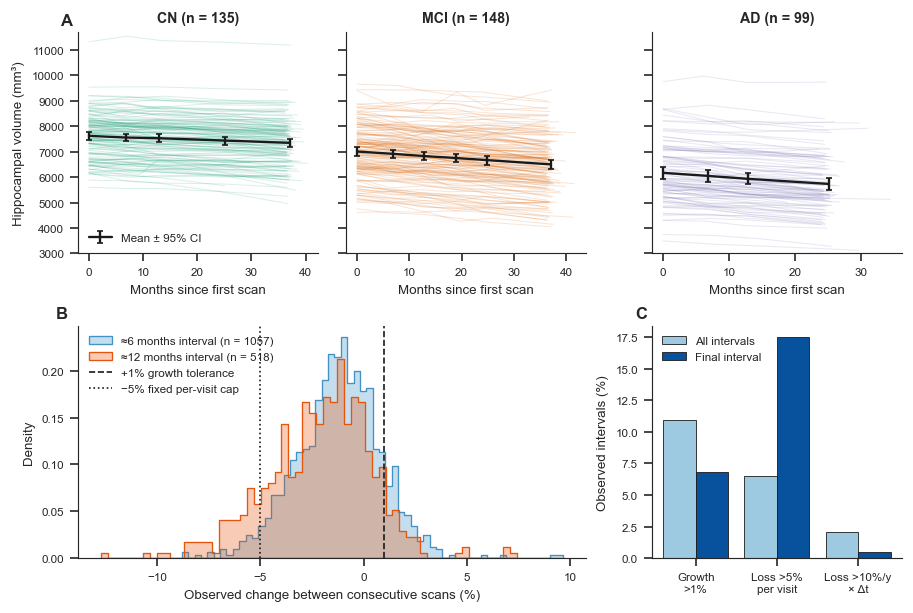

In [6]:
# ---------- Manuscript Fig 3: cohort trajectories and observed change vs corridor ----------
fig = plt.figure(figsize=(FIG_W, 5.0))
gsp = GridSpec(2, 6, figure=fig, height_ratios=[1, 1.05])
axes_top = [fig.add_subplot(gsp[0, 2 * i:2 * i + 2]) for i in range(3)]
for i, (ax, dx) in enumerate(zip(axes_top, DX_ORDER)):
    g = df[df.Diagnosis == dx]
    for _, s in g.groupby('SubjectID'):
        ax.plot(12 * s.t, s.Volume_mm3, color=DX_COL[dx], alpha=0.16, lw=0.6)
    mc = g.groupby('Month').agg(t=('t', 'mean'), v=('Volume_mm3', 'mean'), se=('Volume_mm3', 'sem'))
    ax.errorbar(12 * mc.t, mc.v, yerr=1.96 * mc.se, color='k', lw=1.4, capsize=2, label='Mean ± 95% CI')
    ax.set_title(f'{dx} (n = {g.SubjectID.nunique()})'); ax.set_xlabel('Months since first scan'); ax.set_ylim(3000, 11700)
    if i == 0:
        ax.set_ylabel('Hippocampal volume (mm³)'); ax.legend(frameon=False, loc='lower left'); panel(ax, 'A')
    else:
        ax.set_yticklabels([])
ax = fig.add_subplot(gsp[1, :4]); panel(ax, 'B')
for lab, c in [('≈6 months', '#4292C6'), ('≈12 months', '#E6550D')]:
    sns.histplot(iv.loc[iv.interval == lab, 'pct'], bins=60, stat='density', element='step', fill=True, alpha=0.3, color=c, ax=ax,
                 label=f'{lab} interval (n = {(iv.interval == lab).sum()})')
ax.axvline(100 * CFG['tau_noise'], color='k', ls='--', lw=1, label='+1% growth tolerance')
ax.axvline(-100 * CFG['tau_drop_visit'], color='k', ls=':', lw=1, label='−5% fixed per-visit cap')
ax.set_xlabel('Observed change between consecutive scans (%)'); ax.set_ylabel('Density'); ax.legend(frameon=False, loc='upper left')
ax = fig.add_subplot(gsp[1, 4:]); panel(ax, 'C')
bar = gt_corr.loc[['All intervals', 'Final interval (forecast target)'], ['growth > 1 % (%)', 'loss > 5 %/visit (%)', 'loss > 10 %/y × Δt (%)']]
xs = np.arange(3)
ax.bar(xs - 0.2, bar.iloc[0], 0.4, color='#9ECAE1', edgecolor='k', lw=0.5, label='All intervals')
ax.bar(xs + 0.2, bar.iloc[1], 0.4, color='#08519C', edgecolor='k', lw=0.5, label='Final interval')
ax.set_xticks(xs); ax.set_xticklabels(['Growth\n>1%', 'Loss >5%\nper visit', 'Loss >10%/y\n× Δt'])
ax.set_ylabel('Observed intervals (%)'); ax.legend(frameon=False, loc='upper left')
savefig(fig, 'Fig3_data_and_corridor', plos='Fig3')

## 2. Forecasting task and cross-validation design
* A **window** is a history of ≥ 2 consecutive scans of one subject plus the next scan as the target.
* **T1 (primary):** forecast each subject's final scan from all earlier scans (3–5 scans, horizon ≈ 12 months). There is one target per subject, so 382 out-of-fold forecasts per repeat.
* **T2 (secondary):** every next-scan forecast with ≥ 2 scans of history (6- and 12-month horizons).
* Learned models train on all windows of training subjects. Splits are made at subject level, stratified by diagnosis: 5 folds × 3 repeats.
  An inner 15 % of training subjects is held out for early stopping only.

In [7]:
def build_windows(d, min_hist=2):
    rows = []
    for sid, g in d.groupby('SubjectID', sort=True):
        v, t, m = g.Volume_mm3.to_numpy(float), g.t.to_numpy(float), g.Month.to_numpy()
        for k in range(min_hist, len(v)):
            rows.append(dict(sid=sid, dx=g.dx.iloc[0], age_c=g.age_c.iloc[0], male=g.male.iloc[0], k=k, final=(k == len(v) - 1),
                             hist_v=v[:k], hist_t=t[:k], hist_m=m[:k], v_last=v[k - 1], t_last=t[k - 1],
                             y=v[k], t_target=t[k], dt=t[k] - t[k - 1], month_target=m[k]))
    out = pd.DataFrame(rows); out['wid'] = np.arange(len(out))
    return out

W = build_windows(df)
print(f'windows (T2): {len(W)} | final-scan targets (T1): {W.final.sum()}')
print('T1 history length by diagnosis:', W[W.final].groupby('dx').k.agg(['min', 'max']).to_dict('index'))
print('T1 horizon (years):', W[W.final].dt.describe().round(3).to_dict())

subj_ids, subj_dx = subj.index.to_numpy(), subj.DX.to_numpy()
FOLDS = []
for r in range(CFG['n_repeats']):
    skf = StratifiedKFold(n_splits=CFG['n_folds'], shuffle=True, random_state=CFG['seed'] + r)
    for f, (tr, te) in enumerate(skf.split(subj_ids, subj_dx)):
        inner_tr, inner_val = train_test_split(subj_ids[tr], test_size=CFG['inner_val_frac'], stratify=subj_dx[tr],
                                               random_state=CFG['seed'] + 100 * r + f)
        FOLDS.append(dict(repeat=r, fold=f, train=subj_ids[tr], inner_tr=inner_tr, inner_val=inner_val, test=subj_ids[te],
                          seed=CFG['seed'] + 1000 * r + 10 * f))
for F in FOLDS:
    assert not (set(F['train']) & set(F['test'])) and not (set(F['inner_tr']) & set(F['inner_val']))
for r in range(CFG['n_repeats']):
    allte = np.concatenate([F['test'] for F in FOLDS if F['repeat'] == r])
    assert len(allte) == len(subj_ids) == len(set(allte)), 'each subject must be tested exactly once per repeat'
print(f'{len(FOLDS)} splits | test ≈ {len(FOLDS[0]["test"])} | train {len(FOLDS[0]["inner_tr"])} + inner-val {len(FOLDS[0]["inner_val"])} subjects')

windows (T2): 1193 | final-scan targets (T1): 382
T1 history length by diagnosis: {'AD': {'min': 3, 'max': 3}, 'CN': {'min': 3, 'max': 4}, 'MCI': {'min': 5, 'max': 5}}
T1 horizon (years): {'count': 382.0, 'mean': 1.012, 'std': 0.097, 'min': 0.476, '25%': 0.977, '50%': 1.003, '75%': 1.04, 'max': 1.615}
15 splits | test ≈ 77 | train 259 + inner-val 46 subjects


## 3. Baselines
| Baseline | Definition |
|---|---|
| Persistence | ŷ = last observed volume |
| Population drift | ŷ = v_last·(1 + ρΔt), where ρ is the median annualised relative change in the training windows |
| Linear extrapolation | per-subject OLS line through the history, evaluated at the target date |
| ARIMA(1,1,0) | per-subject ARIMA on the history (falls back to persistence when it cannot be estimated) |
| Linear mixed-effects (LME) | volume ~ time with a random intercept and slope; forecasts use the BLUP given the subject's history |
| LME + covariates | fixed effects time × diagnosis + age + sex + age × time; same random effects |
| XGBoost (± covariates) | gradient boosting on history features (± age, sex, diagnosis), predicting relative change |

In [8]:
def pred_persistence(Wx): return Wx.v_last.to_numpy()
def fit_drift(Wtr): return float(np.median((Wtr.y - Wtr.v_last) / Wtr.v_last / Wtr.dt))
def pred_drift(Wx, rho): return Wx.v_last.to_numpy() * (1 + rho * Wx.dt.to_numpy())

def pred_linear(Wx):
    out = []
    for hv, ht, tt in zip(Wx.hist_v, Wx.hist_t, Wx.t_target):
        b1, b0 = np.polyfit(ht, hv, 1); out.append(b0 + b1 * tt)
    return np.array(out)

class LME:
    """Linear mixed-effects model (random intercept + slope, REML). Forecasts use the BLUP conditioned on the history only."""
    def __init__(self, formula='y ~ t'):
        self.formula = formula
    def fit(self, d):
        dd = d[['SubjectID', 't', 'dx', 'age_c', 'male']].copy()
        dd['y'] = d.Volume_mm3.to_numpy() / 1000.0                 # cm3 for numerical stability
        dd['dx'] = pd.Categorical(dd.dx, DX_ORDER)
        m = smf.mixedlm(self.formula, dd, groups=dd.SubjectID, re_formula='~t')
        self.res = m.fit(reml=True, method=['lbfgs', 'powell'])
        self.beta, self.G, self.s2 = self.res.fe_params.to_numpy(), np.asarray(self.res.cov_re), float(self.res.scale)
        self.design_info = m.data.design_info
        return self
    def _X(self, t, dx, age_c, male):
        nd = pd.DataFrame({'t': t, 'dx': pd.Categorical([dx] * len(t), DX_ORDER), 'age_c': age_c, 'male': male, 'y': 0.0})
        return np.asarray(build_design_matrices([self.design_info], nd)[0])
    def blup(self, ht, hv, Xh):
        Z = np.column_stack([np.ones_like(ht), ht])
        V = Z @ self.G @ Z.T + self.s2 * np.eye(len(ht))
        return self.G @ Z.T @ np.linalg.solve(V, hv / 1000.0 - Xh @ self.beta), Z, V
    def forecast(self, Wx, extra=False):
        P, S, FITS, VAR = [], [], [], []
        for w in Wx.itertuples():
            ht, hv = np.asarray(w.hist_t), np.asarray(w.hist_v)
            Xh = self._X(ht, w.dx, w.age_c, w.male); Xt = self._X(np.array([w.t_target]), w.dx, w.age_c, w.male)[0]
            b, Z, V = self.blup(ht, hv, Xh)
            zt = np.array([1.0, w.t_target])
            P.append(1000 * (Xt @ self.beta + zt @ b))
            if extra:
                FITS.append(1000 * (Xh @ self.beta + Z @ b))
                Xs = self._X(np.array([0.0, 1.0]), w.dx, w.age_c, w.male)
                S.append(1000 * ((Xs[1] - Xs[0]) @ self.beta + b[1]))
                Gpost = self.G - self.G @ Z.T @ np.linalg.solve(V, Z @ self.G)
                VAR.append(1e6 * (zt @ Gpost @ zt + self.s2))        # predictive variance (mm3^2), fixed effects treated as known
        return (np.array(P), np.array(S), FITS, np.array(VAR)) if extra else np.array(P)

def _arima_one(hv):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            return float(ARIMA(hv, order=(1, 1, 0)).fit().forecast(1)[0]), 0
    except Exception:
        return float(hv[-1]), 1

def xgb_features(Wx, covariates=False):
    F = []
    for w in Wx.itertuples():
        hv, ht = np.asarray(w.hist_v), np.asarray(w.hist_t)
        slope = np.polyfit(ht, hv, 1)[0]; last_rate = (hv[-1] - hv[-2]) / (ht[-1] - ht[-2])
        row = [hv[-1], hv[0], hv.mean(), hv.std(), slope, slope / hv[-1], last_rate / hv[-1], len(hv), ht[-1] - ht[0], w.dt]
        if covariates:
            row += [w.age_c, w.male, w.dx == 'MCI', w.dx == 'AD']
        F.append(row)
    return np.asarray(F, dtype=float)

def fit_pred_xgb(Wtr, Wx, seed, covariates=False):
    m = XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                     min_child_weight=5, reg_lambda=1.0, random_state=seed, n_jobs=1)
    m.fit(xgb_features(Wtr, covariates), ((Wtr.y - Wtr.v_last) / Wtr.v_last).to_numpy())
    return Wx.v_last.to_numpy() * (1 + m.predict(xgb_features(Wx, covariates)))

# check: our BLUP reproduces statsmodels' own random-effect estimates
_lme = LME(CFG['lme_formula_cov']).fit(df)
_sid = df.SubjectID.iloc[0]; _g = df[df.SubjectID == _sid]; _w = W[W.sid == _sid].iloc[0]
_b, _, _ = _lme.blup(_g.t.to_numpy(), _g.Volume_mm3.to_numpy(), _lme._X(_g.t.to_numpy(), _w.dx, _w.age_c, _w.male))
print('our BLUP:', _b.round(5), '| statsmodels:', _lme.res.random_effects[_sid].to_numpy().round(5))
assert np.allclose(_b, _lme.res.random_effects[_sid].to_numpy(), atol=1e-4)
print(_lme.res.summary().tables[1])

our BLUP: [0.30228 0.00575] | statsmodels: [0.30228 0.00575]
                Coef. Std.Err.        z  P>|z|  [0.025  0.975]
Intercept       7.316    0.090   81.017  0.000   7.139   7.493
dx[T.MCI]      -0.835    0.109   -7.633  0.000  -1.050  -0.621
dx[T.AD]       -1.507    0.119  -12.663  0.000  -1.741  -1.274
t              -0.089    0.008  -11.912  0.000  -0.104  -0.075
t:dx[T.MCI]    -0.074    0.010   -7.118  0.000  -0.094  -0.054
t:dx[T.AD]     -0.119    0.012   -9.570  0.000  -0.144  -0.095
age_c          -0.510    0.070   -7.281  0.000  -0.647  -0.372
male            0.708    0.095    7.447  0.000   0.522   0.894
age_c:t         0.003    0.007    0.358  0.720  -0.011   0.016
Group Var       0.802    0.708                                
Group x t Cov   0.011    0.044                                
t Var           0.006    0.007                                


In [9]:
def _baseline_fold(F):
    tr, te = W[W.sid.isin(F['train'])], W[W.sid.isin(F['test'])]
    dtr = df[df.SubjectID.isin(F['train'])]
    rho = fit_drift(tr)
    lme0 = LME(CFG['lme_formula_base']).fit(dtr)
    lme1 = LME(CFG['lme_formula_cov']).fit(dtr)
    p1, _, _, var1 = lme1.forecast(te, extra=True)
    # LME fitted on inner-training subjects only -> residuals on inner-validation subjects (for conformal intervals)
    lme1_in = LME(CFG['lme_formula_cov']).fit(df[df.SubjectID.isin(F['inner_tr'])])
    va = W[W.sid.isin(F['inner_val'])]
    preds = {'Persistence': pred_persistence(te), 'Population drift': pred_drift(te, rho), 'Linear extrapolation': pred_linear(te),
             'Linear mixed-effects': lme0.forecast(te), 'Linear mixed-effects + covariates': p1,
             'XGBoost': fit_pred_xgb(tr, te, F['seed']), 'XGBoost + covariates': fit_pred_xgb(tr, te, F['seed'], covariates=True)}
    out = [pd.DataFrame({'model': k, 'repeat': F['repeat'], 'fold': F['fold'], 'wid': te.wid.to_numpy(), 'pred': v,
                         'var': var1 if k == 'Linear mixed-effects + covariates' else np.nan}) for k, v in preds.items()]
    val = pd.DataFrame({'model': 'Linear mixed-effects + covariates', 'repeat': F['repeat'], 'fold': F['fold'],
                        'wid': va.wid.to_numpy(), 'pred': lme1_in.forecast(va)})
    return pd.concat(out), val

def run_baselines():
    t0 = time.time()
    arima = Parallel(n_jobs=CFG['n_jobs'])(delayed(_arima_one)(hv) for hv in W.hist_v)
    arima_pred = np.array([a[0] for a in arima]); arima_fail = np.array([a[1] for a in arima])
    res = Parallel(n_jobs=CFG['n_jobs'])(delayed(_baseline_fold)(F) for F in FOLDS)
    rows = [r[0] for r in res]; vals = pd.concat([r[1] for r in res], ignore_index=True)
    for F in FOLDS:
        te = W[W.sid.isin(F['test'])]
        rows.append(pd.DataFrame({'model': 'ARIMA(1,1,0)', 'repeat': F['repeat'], 'fold': F['fold'], 'wid': te.wid.to_numpy(),
                                  'pred': arima_pred[te.wid.to_numpy()], 'var': np.nan}))
    print(f'baselines done in {time.time() - t0:.0f}s | ARIMA fallback: {arima_fail[W.final.to_numpy()].sum()}/{W.final.sum()} T1, '
          f'{arima_fail.sum()}/{len(W)} T2 windows')
    return dict(preds=pd.concat(rows, ignore_index=True), val=vals, arima_fail=arima_fail)

## 4. Sequence-only RNNs and the biological corridor loss
L = MSE + λ_traj·mean ReLU(Δv)/R + λ_bio·mean ReLU(Δv − τ_noise·v_last)/R + λ_smooth·mean ReLU(−Δv − τ_drop·Δt·v_last)/R, with λ = (1, 2, 1) and τ_noise = 1 %.

**Anchored (default):** the input per step is the scaled volume plus time relative to the last scan. The output is an annualised rate, so ŷ = v_last + r·Δt.
**Absolute-output protocol (Part A):** volume-only input, scaled volume as the direct output, batch 1, 100 epochs, fixed 5 %/visit cap, no validation set.

In [10]:
class Forecaster(nn.Module):
    def __init__(self, cell='gru', in_dim=2, hidden=64, bidirectional=False, head='rate', vmin=0.0, R=1.0, tau_noise=0.01, tau_drop=0.10):
        super().__init__()
        rnn = nn.GRU if cell == 'gru' else nn.LSTM
        self.rnn = rnn(in_dim, hidden, num_layers=1, batch_first=True, bidirectional=bidirectional)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), 1)
        self.cell, self.bi, self.head = cell, bidirectional, head
        self.vmin, self.R, self.tau_noise, self.tau_drop = vmin, R, tau_noise, tau_drop
    def forward(self, x, lengths, x_last, dt):
        _, h = self.rnn(pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False))
        if self.cell == 'lstm':
            h = h[0]
        h = torch.cat([h[-2], h[-1]], dim=-1) if self.bi else h[-1]
        z = self.fc(h).squeeze(-1)
        if self.head == 'absolute':
            return z
        if self.head == 'rate':
            return x_last + z * dt
        if self.head == 'hard':                   # output confined to [v(1 - tau_d*dt), v(1 + tau_n)] by construction
            v_last = x_last * self.R + self.vmin
            frac = self.tau_noise - (self.tau_noise + self.tau_drop * dt) * torch.sigmoid(z)
            return (v_last * (1 + frac) - self.vmin) / self.R
        raise ValueError(self.head)

def corridor_loss(pred, y, x_last, dt, vmin, R, lam, tau_noise, tau_drop, drop_mode='annual'):
    mse = torch.mean((pred - y) ** 2)
    if tuple(lam) == (0, 0, 0):
        return mse
    p_mm, l_mm = pred * R + vmin, x_last * R + vmin
    dv = p_mm - l_mm
    cap = tau_drop * dt if drop_mode == 'annual' else torch.full_like(dt, tau_drop)
    return (mse + lam[0] * torch.relu(dv).mean() / R + lam[1] * torch.relu(dv - tau_noise * l_mm).mean() / R
            + lam[2] * torch.relu(-dv - cap * l_mm).mean() / R)

def tensorize(Wx, vmin, R, n_feat):
    N, L = len(Wx), max(len(h) for h in Wx.hist_v)
    X, lengths = np.zeros((N, L, n_feat), np.float32), np.zeros(N, np.int64)
    for i, (hv, ht) in enumerate(zip(Wx.hist_v, Wx.hist_t)):
        n = len(hv); lengths[i] = n
        X[i, :n, 0] = (hv - vmin) / R
        if n_feat == 2:
            X[i, :n, 1] = ht - ht[-1]
    return dict(X=torch.tensor(X), len=torch.tensor(lengths),
                x_last=torch.tensor(((Wx.v_last.to_numpy() - vmin) / R).astype(np.float32)),
                dt=torch.tensor(Wx.dt.to_numpy().astype(np.float32)),
                y=torch.tensor(((Wx.y.to_numpy() - vmin) / R).astype(np.float32)))

def _batch(T, idx):
    b = {k: v[idx] for k, v in T.items()}
    b['X'] = b['X'][:, :int(b['len'].max())]
    return b

def train_dl(job):
    torch.set_num_threads(1)
    s, seed = job['spec'], job['seed']
    set_seed(seed)
    Wtr, Wval, Wte = job['Wtr'], job['Wval'], job['Wte']
    allv = np.concatenate(list(Wtr.hist_v) + [Wtr.y.to_numpy()])
    vmin, R = float(allv.min()), float(allv.max() - allv.min())
    nf = 2 if s['features'] == 'vol+time' else 1
    model = Forecaster(s['cell'], nf, CFG['hidden'], s['bi'], s['head'], vmin, R, s['tau_noise'], s['tau_drop'])
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr'])
    Ttr, Tte = tensorize(Wtr, vmin, R, nf), tensorize(Wte, vmin, R, nf)
    Tva = tensorize(Wval, vmin, R, nf) if Wval is not None else None
    lossf = lambda b, p: corridor_loss(p, b['y'], b['x_last'], b['dt'], vmin, R, s['lam'], s['tau_noise'], s['tau_drop'], s['drop_mode'])
    gen = torch.Generator().manual_seed(seed)
    N, bs = len(Wtr), s['batch_size']
    curves, best, best_state, wait, best_ep = {'train': [], 'val': []}, np.inf, None, 0, s['epochs'] - 1
    for ep in range(s['epochs']):
        model.train(); tot = 0.0
        perm = torch.randperm(N, generator=gen)
        for i in range(0, N, bs):
            b = _batch(Ttr, perm[i:i + bs])
            loss = lossf(b, model(b['X'], b['len'], b['x_last'], b['dt']))
            opt.zero_grad(); loss.backward()
            if s['grad_clip']:
                nn.utils.clip_grad_norm_(model.parameters(), s['grad_clip'])
            opt.step(); tot += loss.item() * len(b['y'])
        curves['train'].append(tot / N)
        if Tva is not None:
            model.eval()
            with torch.no_grad():
                vl = lossf(Tva, model(Tva['X'], Tva['len'], Tva['x_last'], Tva['dt'])).item()
            curves['val'].append(vl)
            if vl < best - 1e-9:
                best, wait, best_ep = vl, 0, ep
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= s['patience']:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        p = model(Tte['X'], Tte['len'], Tte['x_last'], Tte['dt']).numpy() * R + vmin
    return dict(model=s['name'], repeat=job['repeat'], fold=job['fold'], wid=Wte.wid.to_numpy(), pred=p.astype(float),
                curves=curves, best_epoch=best_ep)

LAM = (CFG['lam_traj'], CFG['lam_bio'], CFG['lam_smooth'])
NOLAM = (0.0, 0.0, 0.0)

def spec(name, cell, bi=False, lam=NOLAM, head='rate', protocol='revised', tau_noise=None, tau_drop=None, drop_mode=None):
    if protocol == 'revised':
        d = dict(features='vol+time', head=head, batch_size=CFG['batch_size'], epochs=CFG['max_epochs'], patience=CFG['patience'],
                 grad_clip=CFG['grad_clip'], drop_mode=drop_mode or 'annual', tau_drop=CFG['tau_drop_annual'] if tau_drop is None else tau_drop)
    else:
        d = dict(features='vol', head='absolute', batch_size=CFG['paper_batch_size'], epochs=CFG['paper_epochs'], patience=None,
                 grad_clip=None, drop_mode='visit', tau_drop=CFG['tau_drop_visit'])
    return dict(name=name, cell=cell, bi=bi, lam=lam, protocol=protocol, tau_noise=CFG['tau_noise'] if tau_noise is None else tau_noise, **d)

MAIN_SPECS = [spec('Standard GRU', 'gru'), spec('Standard LSTM', 'lstm'), spec('Standard Bi-LSTM', 'lstm', bi=True),
              spec('Bio-Informed GRU', 'gru', lam=LAM), spec('Bio-Informed LSTM', 'lstm', lam=LAM),
              spec('Bio-Informed Bi-LSTM', 'lstm', bi=True, lam=LAM), spec('Hard-corridor GRU', 'gru', head='hard')]
PAPER_SPECS = [spec('Standard GRU', 'gru', protocol='paper'), spec('Standard LSTM', 'lstm', protocol='paper'),
               spec('Standard Bi-LSTM', 'lstm', bi=True, protocol='paper'), spec('Bio-Informed GRU', 'gru', lam=LAM, protocol='paper'),
               spec('Bio-Informed LSTM', 'lstm', lam=LAM, protocol='paper'), spec('Bio-Informed Bi-LSTM', 'lstm', bi=True, lam=LAM, protocol='paper')]
L1, L2, L3 = LAM
ABL_SPECS = [spec('MSE + L_traj', 'gru', lam=(L1, 0, 0)), spec('MSE + L_bio', 'gru', lam=(0, L2, 0)),
             spec('MSE + L_smooth', 'gru', lam=(0, 0, L3)), spec('MSE + L_traj + L_bio', 'gru', lam=(L1, L2, 0)),
             spec('Full loss, fixed 5 %/visit cap', 'gru', lam=LAM, drop_mode='visit', tau_drop=CFG['tau_drop_visit'])]
SENS_SPECS = ([spec(f'λ×{k}', 'gru', lam=(k * L1, k * L2, k * L3)) for k in (0.25, 0.5, 2, 4, 8)] +
              [spec(f'τ_noise={tn:g}', 'gru', lam=LAM, tau_noise=tn) for tn in (0.0, 0.005, 0.02)] +
              [spec(f'τ_drop={td:g}/y', 'gru', lam=LAM, tau_drop=td) for td in (0.05, 0.075, 0.15, 0.20)])

def make_jobs(specs, repeats=None):
    jobs = []
    for F in FOLDS:
        if repeats is not None and F['repeat'] not in repeats:
            continue
        for s in specs:
            if s['protocol'] == 'revised':
                Wtr, Wval, Wte = W[W.sid.isin(F['inner_tr'])], W[W.sid.isin(F['inner_val'])], W[W.sid.isin(F['test'])]
            else:
                Wtr, Wval, Wte = W[W.sid.isin(F['train']) & W.final], None, W[W.sid.isin(F['test']) & W.final]
            jobs.append(dict(spec=s, seed=F['seed'], repeat=F['repeat'], fold=F['fold'], Wtr=Wtr, Wval=Wval, Wte=Wte))
    return jobs

def run_parallel(tag, fn, jobs, keys):
    cache = PRED / f'{tag}.pkl'
    if cache.exists() and not FORCE_RERUN:
        print(f'[{tag}] loaded cached results'); return pickle.load(open(cache, 'rb'))
    t0 = time.time(); print(f'[{tag}] training {len(jobs)} networks on {CFG["n_jobs"]} CPU workers ...')
    res = Parallel(n_jobs=CFG['n_jobs'], backend='loky', verbose=2)(delayed(fn)(j) for j in jobs)
    preds = pd.concat([pd.DataFrame({k: r[k] for k in keys}) for r in res], ignore_index=True)
    out = dict(preds=preds, meta=[{k: v for k, v in r.items() if k not in ('wid', 'pred', 'val_wid', 'val_pred')} for r in res],
               val=[{k: r[k] for k in ('model', 'repeat', 'fold', 'val_wid', 'val_pred', 'ens') if k in r} for r in res])
    pickle.dump(out, open(cache, 'wb')); print(f'[{tag}] done in {(time.time() - t0) / 60:.1f} min')
    return out

def run_experiment(tag, specs, repeats=None):
    return run_parallel(tag, train_dl, make_jobs(specs, repeats), ('model', 'repeat', 'fold', 'wid', 'pred'))

## 5. Proposed hybrid: mixed-effects prior + biology-informed RNN correction
For each window, the covariate-adjusted LME supplies a forecast ŷ_LME (BLUP given the history), a subject-specific slope,
and a smoothed history. A GRU reads the scan sequence (scaled volume, relative time, and residual of each scan from the LME fit)
together with static covariates (Δt, age, sex, diagnosis, LME-forecast change, LME slope). It outputs a correction δ, so ŷ = ŷ_LME + δ.
The output layer is zero-initialised, so training starts exactly at the statistical prior. The loss is MSE plus the time-scaled biological corridor.

**Cross-fitting.** The prior for a training window comes from an LME fitted *without that subject* (5-fold inside the training fold).
The network therefore learns to correct genuine out-of-sample forecasts, and test windows use an LME fitted on all training subjects.
**Ensemble.** Five networks with different seeds are averaged (deep ensemble).

In [11]:
def lme_feature_dict(lme, Wx):
    p, s, fits, v = lme.forecast(Wx, extra=True)
    return {wid: (pi, si, fi, vi) for wid, pi, si, fi, vi in zip(Wx.wid, p, s, fits, v)}

def crossfit_features(F, formula):
    """Out-of-subject LME forecasts for all training windows + LME(all training) forecasts for test windows."""
    tr_s = np.array(sorted(F['train'])); dxs = subj.DX.reindex(tr_s).to_numpy()
    Ftr = {}
    for a, b in StratifiedKFold(CFG['hyb_crossfit_k'], shuffle=True, random_state=F['seed']).split(tr_s, dxs):
        Ftr.update(lme_feature_dict(LME(formula).fit(df[df.SubjectID.isin(tr_s[a])]), W[W.sid.isin(tr_s[b])]))
    Fte = lme_feature_dict(LME(formula).fit(df[df.SubjectID.isin(tr_s)]), W[W.sid.isin(F['test'])])
    return (F['repeat'], F['fold'], formula), Ftr, Fte

class HybridRNN(nn.Module):
    def __init__(self, cell='gru', hidden=64, mode='hybrid'):
        super().__init__()
        self.rnn = (nn.GRU if cell == 'gru' else nn.LSTM)(3, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + 8, 32), nn.GELU(), nn.Linear(32, 1))
        nn.init.zeros_(self.head[2].weight); nn.init.zeros_(self.head[2].bias)     # start exactly at the prior
        self.cell, self.mode = cell, mode
    def forward(self, x, lengths, s, x_last, dt, prior):
        _, h = self.rnn(pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False))
        h = (h[0] if self.cell == 'lstm' else h)[-1]
        z = self.head(torch.cat([h, s], -1)).squeeze(-1)
        return prior + z if self.mode == 'hybrid' else x_last + z * dt    # 'rate' = no anchoring on the LME forecast

def tensorize_h(Wx, feats, vmin, R, use_prior=True):
    N, L = len(Wx), max(len(h) for h in Wx.hist_v)
    X = np.zeros((N, L, 3), np.float32); lengths = np.zeros(N, np.int64); S = np.zeros((N, 8), np.float32); prior = np.zeros(N, np.float32)
    for i, w in enumerate(Wx.itertuples()):
        hv, ht = np.asarray(w.hist_v), np.asarray(w.hist_t); n = len(hv); lengths[i] = n
        p, slope, fit, _ = feats[w.wid]
        X[i, :n, 0] = (hv - vmin) / R; X[i, :n, 1] = ht - ht[-1]
        X[i, :n, 2] = (hv - fit) / 100.0 if use_prior else 0.0
        S[i] = [w.dt, w.age_c, w.male, w.dx == 'CN', w.dx == 'MCI', w.dx == 'AD',
                (p - w.v_last) / 100.0 if use_prior else 0.0, slope / 100.0 if use_prior else 0.0]
        prior[i] = (p - vmin) / R
    T = lambda a: torch.tensor(a)
    return dict(X=T(X), len=T(lengths), S=T(S), prior=T(prior), x_last=T(((Wx.v_last.to_numpy() - vmin) / R).astype(np.float32)),
                dt=T(Wx.dt.to_numpy().astype(np.float32)), y=T(((Wx.y.to_numpy() - vmin) / R).astype(np.float32)))

def train_hybrid(job):
    torch.set_num_threads(1)
    s, seed = job['spec'], job['seed']
    set_seed(seed)
    Wtr, Wval, Wte, Ftr, Fte = job['Wtr'], job['Wval'], job['Wte'], job['Ftr'], job['Fte']
    allv = np.concatenate(list(Wtr.hist_v) + [Wtr.y.to_numpy()])
    vmin, R = float(allv.min()), float(allv.max() - allv.min())
    up = s['use_prior']
    Ttr, Tva, Tte = tensorize_h(Wtr, Ftr, vmin, R, up), tensorize_h(Wval, Ftr, vmin, R, up), tensorize_h(Wte, Fte, vmin, R, up)
    model = HybridRNN(s['cell'], CFG['hidden'], s['mode'])
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['hyb_weight_decay'])
    lossf = lambda b, p: corridor_loss(p, b['y'], b['x_last'], b['dt'], vmin, R, s['lam'], CFG['tau_noise'], CFG['tau_drop_annual'])
    fwd = lambda b: model(b['X'], b['len'], b['S'], b['x_last'], b['dt'], b['prior'])
    gen = torch.Generator().manual_seed(seed)
    N, bs = len(Wtr), CFG['batch_size']
    best, best_state, wait, best_ep, curves = np.inf, None, 0, 0, {'train': [], 'val': []}
    for ep in range(CFG['max_epochs']):
        model.train(); tot = 0.0
        perm = torch.randperm(N, generator=gen)
        for i in range(0, N, bs):
            b = _batch(Ttr, perm[i:i + bs])
            loss = lossf(b, fwd(b))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip']); opt.step()
            tot += loss.item() * len(b['y'])
        curves['train'].append(tot / N)
        model.eval()
        with torch.no_grad():
            pv = fwd(Tva); vl = lossf(Tva, pv).item()
        curves['val'].append(vl)
        if vl < best - 1e-9:
            best, wait, best_ep = vl, 0, ep
            best_state = {k: v.clone() for k, v in model.state_dict().items()}; val_pred = pv.numpy() * R + vmin
        else:
            wait += 1
            if wait >= CFG['patience']:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        p = fwd(Tte).numpy() * R + vmin
    return dict(model=s['name'], repeat=job['repeat'], fold=job['fold'], ens=job['ens'], wid=Wte.wid.to_numpy(), pred=p.astype(float),
                val_wid=Wval.wid.to_numpy(), val_pred=val_pred.astype(float), curves=curves, best_epoch=best_ep)

def hspec(name, cell='gru', lam=LAM, mode='hybrid', use_prior=True, prior='cov'):
    return dict(name=name, cell=cell, lam=lam, mode=mode, use_prior=use_prior, prior=prior)

HYB_SPECS = [hspec('Hybrid Bio-Informed GRU'), hspec('Hybrid Bio-Informed LSTM', cell='lstm'), hspec('Hybrid GRU (no corridor)', lam=NOLAM)]
HYB_ABL_SPECS = [hspec('Prior as input (not anchored)', mode='rate'), hspec('No LME prior (covariate RNN)', mode='rate', use_prior=False),
                 hspec('LME prior without covariates', prior='base')]

def hybrid_jobs(specs, FEAT):
    jobs = []
    for F in FOLDS:
        for s in specs:
            form = CFG['lme_formula_cov'] if s['prior'] == 'cov' else CFG['lme_formula_base']
            Ftr, Fte = FEAT[(F['repeat'], F['fold'], form)]
            for e in range(CFG['hyb_ensemble']):
                jobs.append(dict(spec=s, seed=F['seed'] + e, ens=e, repeat=F['repeat'], fold=F['fold'], Wtr=W[W.sid.isin(F['inner_tr'])],
                                 Wval=W[W.sid.isin(F['inner_val'])], Wte=W[W.sid.isin(F['test'])], Ftr=Ftr, Fte=Fte))
    return jobs

## 6. Run all experiments (cached in `results/predictions/`)

In [12]:
cache_b = PRED / 'baselines_v2.pkl'
if cache_b.exists() and not FORCE_RERUN:
    B = pickle.load(open(cache_b, 'rb')); print('[baselines] loaded cached results')
else:
    B = run_baselines(); pickle.dump(B, open(cache_b, 'wb'))

R_main = run_experiment('main_revised', MAIN_SPECS)
R_abl = run_experiment('ablation', ABL_SPECS)
R_sens = run_experiment('sensitivity', SENS_SPECS, repeats=[0])
R_paper = run_experiment('paper_protocol', PAPER_SPECS)

cache_f = PRED / 'hybrid_features.pkl'
if cache_f.exists() and not FORCE_RERUN:
    FEAT = pickle.load(open(cache_f, 'rb')); print('[hybrid features] loaded cached results')
else:
    t0 = time.time()
    fe = Parallel(n_jobs=CFG['n_jobs'])(delayed(crossfit_features)(F, form) for F in FOLDS
                                         for form in (CFG['lme_formula_cov'], CFG['lme_formula_base']))
    FEAT = {k: (a, b) for k, a, b in fe}; pickle.dump(FEAT, open(cache_f, 'wb'))
    print(f'[hybrid features] cross-fitted LME priors in {time.time() - t0:.0f}s')
HKEYS = ('model', 'repeat', 'fold', 'ens', 'wid', 'pred')
R_hyb = run_parallel('hybrid', train_hybrid, hybrid_jobs(HYB_SPECS, FEAT), HKEYS)
R_hyb_abl = run_parallel('hybrid_ablation', train_hybrid, hybrid_jobs(HYB_ABL_SPECS, FEAT), HKEYS)

def ensemble(Rx):
    return Rx['preds'].groupby(['model', 'repeat', 'fold', 'wid'], as_index=False).pred.mean()

_c = R_main['preds'][R_main['preds'].model == 'Standard GRU'].merge(W[['wid', 'v_last', 'dt']], on='wid')
_c['pred'] = np.clip(_c.pred, _c.v_last * (1 - CFG['tau_drop_annual'] * _c.dt), _c.v_last * (1 + CFG['tau_noise']))
P_clip = _c.assign(model='Standard GRU + clip')[['model', 'repeat', 'fold', 'wid', 'pred']]

WINFO = W[['wid', 'sid', 'dx', 'k', 'final', 'v_last', 'y', 'dt', 't_target', 'month_target']]
P_all = pd.concat([B['preds'].drop(columns='var'), R_main['preds'], P_clip, ensemble(R_hyb)], ignore_index=True).merge(WINFO, on='wid')
P_all.to_csv(PRED / 'oof_predictions_all_models.csv', index=False)
print(P_all.groupby('model').size().reindex(MODEL_ORDER))

[baselines] loaded cached results
[main_revised] loaded cached results


[ablation] loaded cached results
[sensitivity] loaded cached results
[paper_protocol] loaded cached results


[hybrid features] loaded cached results
[hybrid] loaded cached results


[hybrid_ablation] loaded cached results


model
Persistence                          3579
Population drift                     3579
Linear extrapolation                 3579
ARIMA(1,1,0)                         3579
Linear mixed-effects                 3579
Linear mixed-effects + covariates    3579
XGBoost                              3579
XGBoost + covariates                 3579
Standard GRU                         3579
Standard LSTM                        3579
Standard Bi-LSTM                     3579
Bio-Informed GRU                     3579
Bio-Informed LSTM                    3579
Bio-Informed Bi-LSTM                 3579
Standard GRU + clip                  3579
Hard-corridor GRU                    3579
Hybrid GRU (no corridor)             3579
Hybrid Bio-Informed LSTM             3579
Hybrid Bio-Informed GRU              3579
dtype: int64


## 7. Metrics
MAE, RMSE, MedAE and MAPE measure accuracy. Skill = 1 − MAE/MAE_persistence. r(change) is the Pearson correlation between predicted and observed change.
The growth-violation rate counts predicted growth above 1 %, and the atrophy-violation rate counts predicted loss above 10 %/y × Δt. MPG is the mean predicted growth among growing forecasts.
Bland–Altman bias and 95 % limits of agreement are also reported. Metrics are computed per repeat on the pooled out-of-fold forecasts and shown as mean ± SD over repeats,
with 95 % CIs from a subject-level bootstrap of repeat-averaged errors.

In [13]:
def metrics(x):
    y, p, vl, dt = x.y.to_numpy(), x.pred.to_numpy(), x.v_last.to_numpy(), x.dt.to_numpy()
    e = p - y; ae = np.abs(e); dp = p - vl; do = y - vl
    ok = np.std(dp) > 1e-9
    return pd.Series({'MAE': ae.mean(), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MedAE': np.median(ae), 'MAPE (%)': 100 * np.mean(ae / y),
                      'r (volume)': stats.pearsonr(y, p)[0], 'r (change)': stats.pearsonr(do, dp)[0] if ok else np.nan,
                      'ρ (change)': stats.spearmanr(do, dp)[0] if ok else np.nan,
                      'Growth violation (%)': 100 * np.mean(dp / vl > CFG['tau_noise']), 'Any growth (%)': 100 * np.mean(dp > 0),
                      'MPG (mm³)': dp[dp > 0].mean() if (dp > 0).any() else 0.0,
                      'Atrophy violation (%)': 100 * np.mean(-dp / vl > CFG['tau_drop_annual'] * dt),
                      'Bias (mm³)': e.mean(), 'LoA low': e.mean() - 1.96 * e.std(ddof=1), 'LoA high': e.mean() + 1.96 * e.std(ddof=1), 'n': len(y)})

def per_repeat(P, task):
    X = P[P.final] if task == 'T1' else P
    return X.groupby(['model', 'repeat'])[['y', 'pred', 'v_last', 'dt']].apply(metrics).reset_index()

def subject_errors(P, task='T1'):
    X = P[P.final] if task == 'T1' else P
    return X.assign(ae=(X.pred - X.y).abs()).groupby(['model', 'wid', 'sid']).ae.mean().reset_index()

def boot_ci(v, level=0.95, n=None, seed=0):
    n = n or CFG['n_boot']; rng = np.random.default_rng(seed)
    bs = rng.choice(v, size=(n, len(v)), replace=True).mean(1)
    a = (1 - level) / 2
    return np.percentile(bs, [100 * a, 100 * (1 - a)])

def summarise(P, task, models=MODEL_ORDER):
    pr = per_repeat(P, task); se = subject_errors(P, task)
    persist = pr[pr.model == 'Persistence'].MAE.mean() if 'Persistence' in pr.model.values else np.nan
    rows = []
    for m in [m for m in models if m in pr.model.values]:
        g = pr[pr.model == m]; ci = boot_ci(se[se.model == m].ae.to_numpy())
        row = {'Model': m, 'MAE mean': g.MAE.mean(), 'MAE sd': g.MAE.std(ddof=1) if len(g) > 1 else 0.0,
               'MAE 95% CI low': ci[0], 'MAE 95% CI high': ci[1], 'Skill vs persistence (%)': 100 * (1 - g.MAE.mean() / persist)}
        for c in ['RMSE', 'MedAE', 'MAPE (%)', 'r (volume)', 'r (change)', 'ρ (change)', 'Growth violation (%)', 'Any growth (%)',
                  'MPG (mm³)', 'Atrophy violation (%)', 'Bias (mm³)', 'LoA low', 'LoA high']:
            row[c] = g[c].mean(); row[c + ' sd'] = g[c].std(ddof=1) if len(g) > 1 else 0.0
        row['n targets'] = int(g.n.iloc[0]); rows.append(row)
    return pd.DataFrame(rows)

def pretty(S):
    f = lambda m, s, d: f'{m:.{d}f} ± {s:.{d}f}'
    return pd.DataFrame({
        'Model': S.Model,
        'MAE (mm³)': [f'{a:.1f} ± {b:.1f} [{c:.1f}, {d:.1f}]' for a, b, c, d in zip(S['MAE mean'], S['MAE sd'], S['MAE 95% CI low'], S['MAE 95% CI high'])],
        'RMSE (mm³)': [f(a, b, 1) for a, b in zip(S.RMSE, S['RMSE sd'])], 'MAPE (%)': [f(a, b, 2) for a, b in zip(S['MAPE (%)'], S['MAPE (%) sd'])],
        'Skill (%)': S['Skill vs persistence (%)'].round(1), 'r (volume)': S['r (volume)'].round(4),
        'r (change)': [f(a, b, 3) if not np.isnan(a) else '—' for a, b in zip(S['r (change)'], S['r (change) sd'])],
        'Growth viol. (%)': [f(a, b, 1) for a, b in zip(S['Growth violation (%)'], S['Growth violation (%) sd'])],
        'MPG (mm³)': S['MPG (mm³)'].round(1),
        'Atrophy viol. (%)': [f(a, b, 1) for a, b in zip(S['Atrophy violation (%)'], S['Atrophy violation (%) sd'])],
        'Bias [LoA] (mm³)': [f'{a:.1f} [{b:.0f}, {c:.0f}]' for a, b, c in zip(S['Bias (mm³)'], S['LoA low'], S['LoA high'])]})

S1 = summarise(P_all, 'T1'); S2 = summarise(P_all, 'T2')
S1.to_csv(TAB / 'Table2_main_T1_full.csv', index=False); S2.to_csv(TAB / 'Table_S2_T2_full.csv', index=False)
save_table(pretty(S1), 'Table2_main_T1'); save_table(pretty(S2), 'Table_S2_all_visits_T2')
print(f'T1 final-scan forecast: {S1["n targets"].iloc[0]} subjects × {CFG["n_repeats"]} repeats')
pretty(S1)

T1 final-scan forecast: 382 subjects × 3 repeats


,Model,MAE (mm³),RMSE (mm³),MAPE (%),Skill (%),r (volume),r (change),Growth viol. (%),MPG (mm³),Atrophy viol. (%),Bias [LoA] (mm³)
0,Persistence,"186.5 ± 0.0 [172.3, 201.0]",230.1 ± 0.0,3.05 ± 0.00,0.0,0.9909,—,0.0 ± 0.0,0.0,0.0 ± 0.0,"153.8 [-182, 490]"
1,Population drift,"141.2 ± 0.2 [130.2, 152.5]",178.9 ± 0.2,2.23 ± 0.00,24.3,0.9909,-0.183 ± 0.006,0.0 ± 0.0,0.0,0.0 ± 0.0,"15.5 [-334, 365]"
2,Linear extrapolation,"144.2 ± 0.0 [130.8, 157.9]",195.7 ± 0.0,2.25 ± 0.00,22.7,0.9876,0.216 ± 0.000,3.1 ± 0.0,52.5,0.0 ± 0.0,"3.3 [-381, 387]"
3,"ARIMA(1,1,0)","184.4 ± 0.0 [171.4, 198.2]",227.4 ± 0.0,2.99 ± 0.00,1.1,0.9904,0.182 ± 0.000,12.3 ± 0.0,57.3,0.0 ± 0.0,"146.3 [-195, 488]"
4,Linear mixed-effects,"121.4 ± 1.7 [110.6, 132.1]",159.7 ± 2.9,1.90 ± 0.03,34.9,0.9917,0.368 ± 0.035,0.2 ± 0.2,39.0,0.0 ± 0.0,"8.1 [-305, 321]"
5,Linear mixed-effects + covariates,"118.2 ± 0.9 [107.8, 128.8]",158.2 ± 1.9,1.85 ± 0.01,36.6,0.9919,0.391 ± 0.019,0.1 ± 0.2,37.9,0.0 ± 0.0,"4.4 [-306, 315]"
6,XGBoost,"126.6 ± 1.7 [116.2, 137.3]",165.1 ± 2.2,1.98 ± 0.02,32.1,0.9912,0.302 ± 0.027,0.3 ± 0.3,57.4,0.0 ± 0.0,"9.6 [-314, 333]"
7,XGBoost + covariates,"124.5 ± 2.5 [114.4, 135.1]",163.2 ± 3.2,1.95 ± 0.03,33.2,0.9913,0.325 ± 0.038,0.1 ± 0.2,40.5,0.0 ± 0.0,"2.7 [-318, 323]"
8,Standard GRU,"129.1 ± 0.3 [118.6, 139.9]",167.8 ± 0.7,2.03 ± 0.01,30.8,0.9909,0.239 ± 0.018,0.0 ± 0.0,36.1,0.1 ± 0.2,"11.6 [-317, 340]"
9,Standard LSTM,"128.8 ± 1.3 [118.0, 139.8]",167.7 ± 1.7,2.02 ± 0.02,30.9,0.9909,0.229 ± 0.038,0.1 ± 0.2,54.4,0.0 ± 0.0,"8.8 [-320, 338]"


In [14]:
print('T2: all next-scan forecasts'); pretty(S2)

T2: all next-scan forecasts


,Model,MAE (mm³),RMSE (mm³),MAPE (%),Skill (%),r (volume),r (change),Growth viol. (%),MPG (mm³),Atrophy viol. (%),Bias [LoA] (mm³)
0,Persistence,"143.6 ± 0.0 [137.1, 150.2]",184.9 ± 0.0,2.24 ± 0.00,0.0,0.9916,—,0.0 ± 0.0,0.0,0.0 ± 0.0,"102.7 [-199, 404]"
1,Population drift,"119.2 ± 0.1 [113.6, 125.0]",154.7 ± 0.1,1.80 ± 0.00,17.0,0.9919,0.114 ± 0.002,0.0 ± 0.0,0.0,0.0 ± 0.0,"1.4 [-302, 305]"
2,Linear extrapolation,"143.8 ± 0.0 [136.3, 151.3]",192.8 ± 0.0,2.16 ± 0.00,-0.2,0.9868,0.062 ± 0.000,6.0 ± 0.0,64.4,0.9 ± 0.0,"0.3 [-378, 378]"
3,"ARIMA(1,1,0)","141.4 ± 0.0 [134.7, 148.2]",183.3 ± 0.0,2.20 ± 0.00,1.5,0.9911,0.111 ± 0.000,6.0 ± 0.0,45.2,0.0 ± 0.0,"92.3 [-218, 403]"
4,Linear mixed-effects,"109.0 ± 0.7 [103.6, 114.1]",142.9 ± 1.1,1.65 ± 0.01,24.1,0.9927,0.380 ± 0.010,0.8 ± 0.1,35.1,0.0 ± 0.0,"0.1 [-280, 280]"
5,Linear mixed-effects + covariates,"106.3 ± 0.6 [101.0, 111.5]",140.7 ± 1.3,1.61 ± 0.01,25.9,0.9929,0.411 ± 0.012,0.9 ± 0.4,35.3,0.0 ± 0.0,"0.2 [-276, 276]"
6,XGBoost,"113.0 ± 0.4 [107.6, 118.2]",148.0 ± 0.4,1.71 ± 0.01,21.3,0.9921,0.312 ± 0.002,0.5 ± 0.3,33.0,0.1 ± 0.0,"-0.7 [-291, 290]"
7,XGBoost + covariates,"110.2 ± 0.6 [104.9, 115.4]",145.3 ± 0.7,1.66 ± 0.01,23.2,0.9924,0.352 ± 0.009,0.4 ± 0.2,29.2,0.1 ± 0.1,"-1.0 [-286, 284]"
8,Standard GRU,"113.0 ± 0.3 [107.8, 118.3]",148.1 ± 0.4,1.71 ± 0.00,21.3,0.9921,0.280 ± 0.010,0.0 ± 0.0,28.0,0.1 ± 0.1,"3.0 [-287, 293]"
9,Standard LSTM,"113.1 ± 0.4 [107.9, 118.6]",148.4 ± 0.6,1.71 ± 0.01,21.2,0.9921,0.272 ± 0.014,0.1 ± 0.1,37.8,0.0 ± 0.0,"1.5 [-289, 292]"


## 8. Statistical comparisons and equivalence
Paired two-sided Wilcoxon signed-rank tests on per-subject absolute errors (T1, averaged over repeats), Holm-corrected over the planned family.
Equivalence between the proposed hybrid and the covariate LME is tested with paired TOST, using a pre-specified margin of ±5 mm³.
The margin is about 7 % of the within-subject measurement noise and below 0.1 % of hippocampal volume.

In [15]:
SE1 = subject_errors(P_all, 'T1').pivot(index='sid', columns='model', values='ae')

def compare(a, b, E=SE1, seed=0):
    d = (E[a] - E[b]).dropna().to_numpy()
    p = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    ci = boot_ci(d, seed=seed)
    return {'A': a, 'B': b, 'MAE A': E[a].mean(), 'MAE B': E[b].mean(), 'ΔMAE (A−B)': d.mean(), 'CI low': ci[0], 'CI high': ci[1],
            'A better in (% subjects)': 100 * np.mean(d < 0), 'p (Wilcoxon)': p}

planned = [(PROPOSED, b) for b in BASELINES] + [(PROPOSED, 'Bio-Informed GRU'), (PROPOSED, 'Standard GRU'), (PROPOSED, 'Hybrid GRU (no corridor)')]
planned += [(f'Bio-Informed {a}', f'Standard {a}') for a in ('GRU', 'LSTM', 'Bi-LSTM')]
CMP = pd.DataFrame([compare(a, b, seed=i) for i, (a, b) in enumerate(planned)])
CMP['p (Holm)'] = multipletests(CMP['p (Wilcoxon)'], method='holm')[1]
CMP['significant'] = CMP['p (Holm)'] < CFG['alpha']
save_table(CMP.round(5), 'Table3_statistical_tests')

EQ = []
for b in ['Linear mixed-effects + covariates', 'Linear mixed-effects', 'XGBoost + covariates']:
    d = (SE1[PROPOSED] - SE1[b]).to_numpy(); M = CFG['equivalence_margin']
    p_tost = ttost_paired(SE1[PROPOSED].to_numpy(), SE1[b].to_numpy(), -M, M)[0]
    ci90 = boot_ci(d, level=0.90)
    EQ.append({'A': PROPOSED, 'B': b, 'ΔMAE': d.mean(), '90% CI low': ci90[0], '90% CI high': ci90[1], 'margin': M,
               'p (TOST)': p_tost, 'equivalent': (p_tost < CFG['alpha']) and (ci90[0] > -M) and (ci90[1] < M)})
EQ = pd.DataFrame(EQ); save_table(EQ.round(5), 'Table3b_equivalence')
display(CMP.round(4)); EQ.round(4)

,A,B,MAE A,MAE B,ΔMAE (A−B),CI low,CI high,A better in (% subjects),p (Wilcoxon),p (Holm),significant
0,Hybrid Bio-Informed GRU,Persistence,120.9647,186.4767,-65.5120,-77.5265,-53.6957,71.4660,0.0000,0.0000,True
1,Hybrid Bio-Informed GRU,Population drift,120.9647,141.2328,-20.2680,-26.4035,-13.9847,63.8743,0.0000,0.0000,True
2,Hybrid Bio-Informed GRU,Linear extrapolation,120.9647,144.2105,-23.2458,-33.0840,-13.6361,57.0681,0.0001,0.0008,True
3,Hybrid Bio-Informed GRU,"ARIMA(1,1,0)",120.9647,184.3522,-63.3874,-75.6739,-51.3349,70.9424,0.0000,0.0000,True
4,Hybrid Bio-Informed GRU,Linear mixed-effects,120.9647,121.3689,-0.4042,-3.5516,2.7480,54.4503,0.3516,1.0000,False
5,Hybrid Bio-Informed GRU,Linear mixed-effects + covariates,120.9647,118.2138,2.7509,0.0218,5.4388,45.2880,0.0367,0.2566,False
6,Hybrid Bio-Informed GRU,XGBoost,120.9647,126.5570,-5.5923,-10.7809,-0.5281,54.9738,0.0124,0.0995,False
7,Hybrid Bio-Informed GRU,XGBoost + covariates,120.9647,124.4913,-3.5266,-8.0090,0.8675,52.8796,0.1422,0.5688,False
8,Hybrid Bio-Informed GRU,Bio-Informed GRU,120.9647,130.2329,-9.2682,-13.0665,-5.4155,57.3298,0.0000,0.0001,True
9,Hybrid Bio-Informed GRU,Standard GRU,120.9647,129.1255,-8.1607,-11.6875,-4.5604,58.1152,0.0001,0.0006,True


,A,B,ΔMAE,90% CI low,90% CI high,margin,p (TOST),equivalent
0,Hybrid Bio-Informed GRU,Linear mixed-effects + covariates,2.7509,0.4859,4.9312,5.0,0.0475,True
1,Hybrid Bio-Informed GRU,Linear mixed-effects,-0.4042,-3.1211,2.2600,5.0,0.0026,True
2,Hybrid Bio-Informed GRU,XGBoost + covariates,-3.5266,-7.1918,0.0796,5.0,0.2606,False


In [16]:
# Growth-violation difference (Bio vs Standard, same architecture), subject-level bootstrap
X1 = P_all[P_all.final].copy()
X1['gv'] = ((X1.pred - X1.v_last) / X1.v_last > CFG['tau_noise']).astype(float)
GV = X1.groupby(['model', 'sid']).gv.mean().unstack(0)
rows = []
for a in ('GRU', 'LSTM', 'Bi-LSTM'):
    d = (GV[f'Bio-Informed {a}'] - GV[f'Standard {a}']).to_numpy() * 100; ci = boot_ci(d)
    rows.append({'Architecture': a, 'Standard (%)': GV[f'Standard {a}'].mean() * 100, 'Bio-Informed (%)': GV[f'Bio-Informed {a}'].mean() * 100,
                 'Difference (pp)': d.mean(), '95% CI': f'[{ci[0]:.2f}, {ci[1]:.2f}]'})
VIOL = pd.DataFrame(rows).round(2); save_table(VIOL, 'Table_S3_violation_difference'); VIOL

,Architecture,Standard (%),Bio-Informed (%),Difference (pp),95% CI
0,GRU,0.00,0.0,0.00,"[0.00, 0.00]"
1,LSTM,0.09,0.0,-0.09,"[-0.26, 0.00]"
2,Bi-LSTM,0.00,0.0,0.00,"[0.00, 0.00]"


## 9. Prediction intervals
* **LME (analytic):** ŷ ± z·σ̂, where σ̂² is the BLUP posterior variance plus the residual variance.
* **Split-conformal:** ŷ ± q, where q is the ⌈(n+1)(1−α)⌉-th smallest absolute residual on the inner-validation subjects' final scans.
  For the hybrid, these are the early-stopping subjects. For the LME, a second model is fitted on inner-training subjects only. Nothing is calibrated on test subjects.

In [17]:
LEVELS = [0.5, 0.8, 0.9, 0.95]
def conformal_q(res_abs, level):
    n = len(res_abs); k = int(np.ceil((n + 1) * level))
    return np.sort(res_abs)[min(k, n) - 1]

final_w = set(W.wid[W.final])
hv = pd.DataFrame([{'repeat': v['repeat'], 'fold': v['fold'], 'ens': v['ens'], 'wid': w, 'pred': p}
                   for v in R_hyb['val'] if v['model'] == PROPOSED for w, p in zip(v['val_wid'], v['val_pred'])])
hv = hv.groupby(['repeat', 'fold', 'wid'], as_index=False).pred.mean().merge(WINFO[['wid', 'y', 'final']], on='wid')
lv = B['val'].merge(WINFO[['wid', 'y', 'final']], on='wid')
lme_te = B['preds'][B['preds'].model == 'Linear mixed-effects + covariates'].merge(WINFO[['wid', 'y', 'final', 'sid']], on='wid')
hyb_te = P_all[(P_all.model == PROPOSED)]
cov_rows, IV = [], []
for (r, f), g in hyb_te[hyb_te.final].groupby(['repeat', 'fold']):
    resid_h = (hv[(hv.repeat == r) & (hv.fold == f) & hv.final].pred - hv[(hv.repeat == r) & (hv.fold == f) & hv.final].y).abs().to_numpy()
    resid_l = (lv[(lv.repeat == r) & (lv.fold == f) & lv.final].pred - lv[(lv.repeat == r) & (lv.fold == f) & lv.final].y).abs().to_numpy()
    gl = lme_te[(lme_te.repeat == r) & (lme_te.fold == f) & lme_te.final]
    for lev in LEVELS:
        qh, ql = conformal_q(resid_h, lev), conformal_q(resid_l, lev); z = stats.norm.ppf(0.5 + lev / 2)
        for name, pred, y, half in [('Hybrid (conformal)', g.pred.to_numpy(), g.y.to_numpy(), np.full(len(g), qh)),
                                    ('LME + cov. (conformal)', gl.pred.to_numpy(), gl.y.to_numpy(), np.full(len(gl), ql)),
                                    ('LME + cov. (analytic)', gl.pred.to_numpy(), gl.y.to_numpy(), z * np.sqrt(gl['var'].to_numpy()))]:
            cov_rows.append({'method': name, 'level': lev, 'repeat': r, 'fold': f, 'covered': np.mean(np.abs(y - pred) <= half) * len(y),
                             'n': len(y), 'width_sum': (2 * half).sum()})
        if lev == 0.9:
            IV.append(g.assign(lo=g.pred - qh, hi=g.pred + qh))
COV = pd.DataFrame(cov_rows).groupby(['method', 'level'])[['covered', 'n', 'width_sum']].sum()
COV['coverage (%)'] = 100 * COV.covered / COV.n; COV['mean width (mm³)'] = COV.width_sum / COV.n
COV = COV[['coverage (%)', 'mean width (mm³)']].round(1).reset_index()
IV = pd.concat(IV)
save_table(COV, 'Table_S7_interval_coverage'); COV

,method,level,coverage (%),mean width (mm³)
0,Hybrid (conformal),0.50,50.7,194.2
1,Hybrid (conformal),0.80,78.9,371.1
2,Hybrid (conformal),0.90,89.4,529.8
3,Hybrid (conformal),0.95,95.5,685.9
4,LME + cov. (analytic),0.50,52.6,197.8
5,LME + cov. (analytic),0.80,80.1,375.9
6,LME + cov. (analytic),0.90,89.4,482.5
7,LME + cov. (analytic),0.95,93.6,574.9
8,LME + cov. (conformal),0.50,52.8,196.7
9,LME + cov. (conformal),0.80,81.8,396.4


## 10. Ablations and sensitivity

In [18]:
P_abl = pd.concat([R_abl['preds'], R_main['preds'][R_main['preds'].model.isin(['Standard GRU', 'Bio-Informed GRU'])]]).merge(WINFO, on='wid')
P_abl['model'] = P_abl.model.replace({'Standard GRU': 'MSE only (Standard GRU)', 'Bio-Informed GRU': 'Full loss (Bio-Informed GRU)'})
ABL_ORDER = ['MSE only (Standard GRU)', 'MSE + L_traj', 'MSE + L_bio', 'MSE + L_smooth', 'MSE + L_traj + L_bio',
             'Full loss (Bio-Informed GRU)', 'Full loss, fixed 5 %/visit cap']
SA = summarise(P_abl, 'T1', ABL_ORDER)
SE_abl = subject_errors(P_abl, 'T1').pivot(index='sid', columns='model', values='ae')
ps = [compare(m, 'MSE only (Standard GRU)', E=SE_abl)['p (Wilcoxon)'] for m in ABL_ORDER[1:]]
SA['p vs MSE only (Holm)'] = [np.nan] + list(multipletests(ps, method='holm')[1])
ABL = SA[['Model', 'MAE mean', 'MAE sd', 'MAE 95% CI low', 'MAE 95% CI high', 'r (change)', 'Growth violation (%)', 'Atrophy violation (%)', 'p vs MSE only (Holm)']].round(3)
save_table(ABL, 'Table4a_corridor_ablation'); ABL

,Model,MAE mean,MAE sd,MAE 95% CI low,MAE 95% CI high,r (change),Growth violation (%),Atrophy violation (%),p vs MSE only (Holm)
0,MSE only (Standard GRU),129.125,0.300,118.600,139.892,0.239,0.0,0.087,NaN
1,MSE + L_traj,130.555,0.107,119.539,141.501,0.181,0.0,0.000,1.000
2,MSE + L_bio,130.513,1.816,119.646,141.416,0.198,0.0,0.087,0.661
3,MSE + L_smooth,130.018,1.243,119.251,141.077,0.213,0.0,0.000,1.000
4,MSE + L_traj + L_bio,130.482,0.451,119.547,141.502,0.177,0.0,0.000,1.000
5,Full loss (Bio-Informed GRU),130.233,1.255,119.188,141.260,0.183,0.0,0.000,1.000
6,"Full loss, fixed 5 %/visit cap",133.000,0.423,122.132,144.426,0.106,0.0,0.000,0.178


In [19]:
single = R_hyb['preds'][(R_hyb['preds'].model == PROPOSED) & (R_hyb['preds'].ens == 0)].assign(model='Single network (no ensemble)')
P_habl = pd.concat([ensemble(R_hyb), ensemble(R_hyb_abl), single[['model', 'repeat', 'fold', 'wid', 'pred']],
                    B['preds'][B['preds'].model == 'Linear mixed-effects + covariates'].drop(columns='var')]).merge(WINFO, on='wid')
HABL_ORDER = ['Linear mixed-effects + covariates', PROPOSED, 'Hybrid GRU (no corridor)', 'Single network (no ensemble)',
              'Prior as input (not anchored)', 'LME prior without covariates', 'No LME prior (covariate RNN)']
SH = summarise(P_habl, 'T1', HABL_ORDER)
SE_h = subject_errors(P_habl, 'T1').pivot(index='sid', columns='model', values='ae')
ps = [compare(m, PROPOSED, E=SE_h)['p (Wilcoxon)'] for m in HABL_ORDER if m != PROPOSED]
SH['p vs proposed (Holm)'] = np.nan
SH.loc[SH.Model != PROPOSED, 'p vs proposed (Holm)'] = multipletests(ps, method='holm')[1]
HABL = SH[['Model', 'MAE mean', 'MAE sd', 'MAE 95% CI low', 'MAE 95% CI high', 'r (change)', 'Growth violation (%)', 'Atrophy violation (%)', 'p vs proposed (Holm)']].round(3)
save_table(HABL, 'Table4b_hybrid_ablation'); HABL

,Model,MAE mean,MAE sd,MAE 95% CI low,MAE 95% CI high,r (change),Growth violation (%),Atrophy violation (%),p vs proposed (Holm)
0,Linear mixed-effects + covariates,118.214,0.875,107.788,128.844,0.391,0.087,0.0,0.183
1,Hybrid Bio-Informed GRU,120.965,0.381,110.270,131.463,0.355,0.000,0.0,NaN
2,Hybrid GRU (no corridor),120.222,1.026,109.214,131.125,0.337,0.087,0.0,0.246
3,Single network (no ensemble),121.183,0.880,110.460,131.675,0.347,0.000,0.0,0.853
4,Prior as input (not anchored),121.321,0.174,110.072,132.194,0.318,0.000,0.0,0.853
5,LME prior without covariates,121.652,0.245,110.941,132.316,0.337,0.000,0.0,0.847
6,No LME prior (covariate RNN),129.472,0.705,118.697,140.233,0.196,0.000,0.0,0.000


In [20]:
DEF = 'default (λ×1, τ_noise=0.01, τ_drop=0.1/y)'
P_sens = pd.concat([R_sens['preds'], R_main['preds'][(R_main['preds'].model == 'Bio-Informed GRU') & (R_main['preds'].repeat == 0)]
                    .assign(model=DEF)]).merge(WINFO, on='wid')
SS = summarise(P_sens, 'T1', [s['name'] for s in SENS_SPECS] + [DEF])
SENS = SS[['Model', 'MAE mean', 'MAE 95% CI low', 'MAE 95% CI high', 'r (change)', 'Growth violation (%)', 'Atrophy violation (%)']].round(3)
save_table(SENS, 'Table_S4_sensitivity'); SENS

,Model,MAE mean,MAE 95% CI low,MAE 95% CI high,r (change),Growth violation (%),Atrophy violation (%)
0,λ×0.25,129.403,118.401,140.615,0.204,0.0,0.0
1,λ×0.5,129.500,118.406,140.684,0.195,0.0,0.0
2,λ×2,130.445,119.157,141.951,0.173,0.0,0.0
3,λ×4,130.707,119.685,142.114,0.170,0.0,0.0
4,λ×8,129.576,118.381,140.862,0.189,0.0,0.0
5,τ_noise=0,129.722,118.462,140.961,0.196,0.0,0.0
6,τ_noise=0.005,129.001,117.826,140.159,0.204,0.0,0.0
7,τ_noise=0.02,129.628,118.463,140.836,0.193,0.0,0.0
8,τ_drop=0.05/y,131.120,119.871,142.740,0.163,0.0,0.0
9,τ_drop=0.075/y,130.538,119.209,141.820,0.183,0.0,0.0


## 11. Part A: absolute-output (non-anchored) RNN protocol
Volume-only input, the scaled volume as the direct output, batch 1, 100 epochs, fixed 5 %/visit cap, no validation set. This is the design used in much of the literature.

In [21]:
P_pap = pd.concat([R_paper['preds'].merge(WINFO, on='wid'), P_all[P_all.final & P_all.model.isin(['Persistence', 'ARIMA(1,1,0)'])]], ignore_index=True)
SP = summarise(P_pap, 'T1', ['Persistence', 'ARIMA(1,1,0)'] + [s['name'] for s in PAPER_SPECS])
SE_pap = subject_errors(P_pap, 'T1').pivot(index='sid', columns='model', values='ae')
CP = pd.DataFrame([compare(f'Bio-Informed {a}', f'Standard {a}', E=SE_pap) for a in ('GRU', 'LSTM', 'Bi-LSTM')])
CP['p (Holm)'] = multipletests(CP['p (Wilcoxon)'], method='holm')[1]
fold_mae = P_pap[P_pap.final].assign(ae=lambda x: (x.pred - x.y).abs()).groupby(['model', 'repeat', 'fold']).ae.mean().reset_index()
rng_tab = fold_mae.groupby('model').ae.agg(['min', 'max', 'mean']).round(1)
SPT = SP.copy(); SPT['fold MAE min'] = SPT.Model.map(rng_tab['min']); SPT['fold MAE max'] = SPT.Model.map(rng_tab['max'])
save_table(pretty(SP).assign(**{'Per-fold MAE range': [f"{a:.0f}–{b:.0f}" for a, b in zip(SPT['fold MAE min'], SPT['fold MAE max'])]}),
           'Table_S5_absolute_output_protocol')
SPT.to_csv(TAB / 'Table_S5_absolute_output_protocol_full.csv', index=False)
save_table(CP.round(5), 'Table_S5b_absolute_output_tests')
display(pretty(SP)); display(CP.round(4)); rng_tab

,Model,MAE (mm³),RMSE (mm³),MAPE (%),Skill (%),r (volume),r (change),Growth viol. (%),MPG (mm³),Atrophy viol. (%),Bias [LoA] (mm³)
0,Persistence,"186.5 ± 0.0 [172.3, 201.0]",230.1 ± 0.0,3.05 ± 0.00,0.0,0.9909,—,0.0 ± 0.0,0.0,0.0 ± 0.0,"153.8 [-182, 490]"
1,"ARIMA(1,1,0)","184.4 ± 0.0 [171.4, 198.2]",227.4 ± 0.0,2.99 ± 0.00,1.1,0.9904,0.182 ± 0.000,12.3 ± 0.0,57.3,0.0 ± 0.0,"146.3 [-195, 488]"
2,Standard GRU,"133.9 ± 8.7 [123.6, 144.5]",174.3 ± 9.2,2.10 ± 0.14,28.2,0.9905,0.272 ± 0.062,0.8 ± 0.9,48.9,0.1 ± 0.2,"-22.2 [-357, 313]"
3,Standard LSTM,"138.5 ± 9.9 [128.6, 148.6]",178.8 ± 9.6,2.17 ± 0.15,25.7,0.9901,0.244 ± 0.052,1.2 ± 1.3,54.1,0.2 ± 0.3,"-24.9 [-366, 317]"
4,Standard Bi-LSTM,"138.9 ± 5.1 [129.0, 148.9]",179.5 ± 6.8,2.18 ± 0.08,25.5,0.9901,0.250 ± 0.046,1.2 ± 1.5,48.3,0.2 ± 0.3,"-24.7 [-368, 318]"
5,Bio-Informed GRU,"136.2 ± 6.6 [126.3, 146.6]",174.7 ± 7.7,2.11 ± 0.08,27.0,0.9908,0.124 ± 0.087,0.1 ± 0.2,19.6,0.0 ± 0.0,"-8.5 [-349, 332]"
6,Bio-Informed LSTM,"143.8 ± 15.0 [134.1, 154.1]",183.7 ± 16.6,2.24 ± 0.18,22.9,0.9905,0.069 ± 0.155,0.2 ± 0.3,11.7,0.0 ± 0.0,"-11.3 [-358, 335]"
7,Bio-Informed Bi-LSTM,"143.9 ± 8.8 [133.8, 154.3]",184.0 ± 10.9,2.22 ± 0.10,22.8,0.9901,0.062 ± 0.059,0.0 ± 0.0,0.0,0.0 ± 0.0,"-20.1 [-374, 334]"


,A,B,MAE A,MAE B,ΔMAE (A−B),CI low,CI high,A better in (% subjects),p (Wilcoxon),p (Holm)
0,Bio-Informed GRU,Standard GRU,136.2062,133.8506,2.3556,-3.8360,8.7152,47.1204,0.5948,0.7080
1,Bio-Informed LSTM,Standard LSTM,143.7639,138.5371,5.2268,-0.4354,10.9071,47.6440,0.2178,0.6533
2,Bio-Informed Bi-LSTM,Standard Bi-LSTM,143.8720,138.9280,4.9440,-2.2060,12.0948,48.9529,0.3540,0.7080


,min,max,mean
model,,,
"ARIMA(1,1,0)",149.4,211.9,184.4
Bio-Informed Bi-LSTM,115.0,190.3,143.8
Bio-Informed GRU,110.9,183.9,136.2
Bio-Informed LSTM,113.3,195.4,143.7
Persistence,150.7,213.8,186.5
Standard Bi-LSTM,110.0,187.8,139.0
Standard GRU,110.7,186.5,133.9
Standard LSTM,108.0,186.2,138.6


## 12. Figures

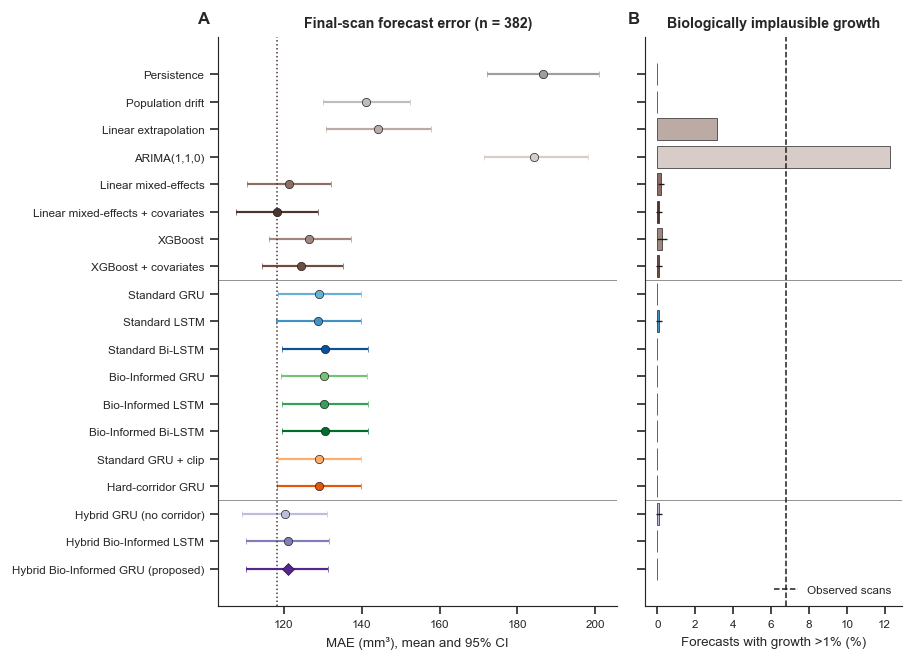

In [22]:
# Manuscript Fig 4: accuracy (MAE, 95% CI) and implausible growth
S_plot = S1.set_index('Model').reindex([m for m in MODEL_ORDER if m in S1.Model.values])
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 5.4), sharey=True, gridspec_kw={'width_ratios': [1.55, 1]})
yy = np.arange(len(S_plot))[::-1]
ax = axes[0]; panel(ax, 'A')
for sep in (len(HYB_MODELS) - 0.5, len(HYB_MODELS) + len(SEQ_MODELS) - 0.5):
    ax.axhline(sep, color='grey', lw=0.5, ls='-'); axes[1].axhline(sep, color='grey', lw=0.5)
for yi, (m, r) in zip(yy, S_plot.iterrows()):
    ax.errorbar(r['MAE mean'], yi, xerr=[[r['MAE mean'] - r['MAE 95% CI low']], [r['MAE 95% CI high'] - r['MAE mean']]],
                fmt='D' if m == PROPOSED else 'o', color=PALETTE[m], ms=5, capsize=2, lw=1.3, mec='k', mew=0.4)
ax.axvline(S_plot.loc['Linear mixed-effects + covariates', 'MAE mean'], color=PALETTE['Linear mixed-effects + covariates'], ls=':', lw=0.9)
ax.set_yticks(yy); ax.set_yticklabels([f'{m} (proposed)' if m == PROPOSED else m for m in S_plot.index])
ax.set_xlabel('MAE (mm³), mean and 95% CI'); ax.set_title('Final-scan forecast error (n = 382)')
ax = axes[1]; panel(ax, 'B')
ax.barh(yy, S_plot['Growth violation (%)'], xerr=S_plot['Growth violation (%) sd'], color=[PALETTE[m] for m in S_plot.index],
        edgecolor='k', lw=0.4, error_kw={'lw': 0.8})
ax.axvline(gt_corr.loc['Final interval (forecast target)', 'growth > 1 % (%)'], color='k', ls='--', lw=0.9, label='Observed scans')
ax.set_xlabel('Forecasts with growth >1% (%)'); ax.set_title('Biologically implausible growth'); ax.legend(frameon=False, loc='lower right')
savefig(fig, 'Fig4_accuracy_and_violations', plos='Fig4')

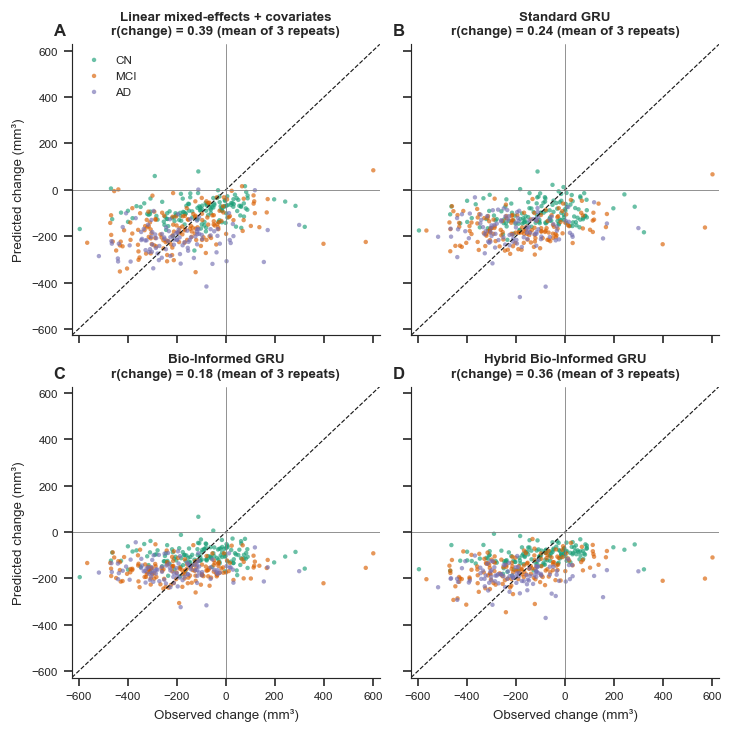

In [23]:
# Manuscript Fig 7: predicted vs observed change
key = ['Linear mixed-effects + covariates', 'Standard GRU', 'Bio-Informed GRU', PROPOSED]
X1r = P_all[P_all.final & (P_all.repeat == 0)]
fig, axes = plt.subplots(2, 2, figsize=(FIG_W * 0.8, FIG_W * 0.8), sharex=True, sharey=True)
lim = np.percentile(np.abs(X1r.y - X1r.v_last), 99) * 1.1
for ax, m, L in zip(axes.ravel(), key, 'ABCD'):
    x = X1r[X1r.model == m]
    for dx in DX_ORDER:
        xs = x[x.dx == dx]
        ax.scatter(xs.y - xs.v_last, xs.pred - xs.v_last, s=7, alpha=0.65, color=DX_COL[dx], label=dx, edgecolor='none')
    ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.7); ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    r = S1.set_index('Model').loc[m, 'r (change)']
    ax.set_title(f'{m}\nr(change) = {r:.2f} (mean of 3 repeats)', fontsize=8); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); panel(ax, L)
for ax in axes[1]: ax.set_xlabel('Observed change (mm³)')
for ax in axes[:, 0]: ax.set_ylabel('Predicted change (mm³)')
axes[0, 0].legend(frameon=False, loc='upper left')
savefig(fig, 'Fig7_predicted_vs_observed_change', plos='Fig7')

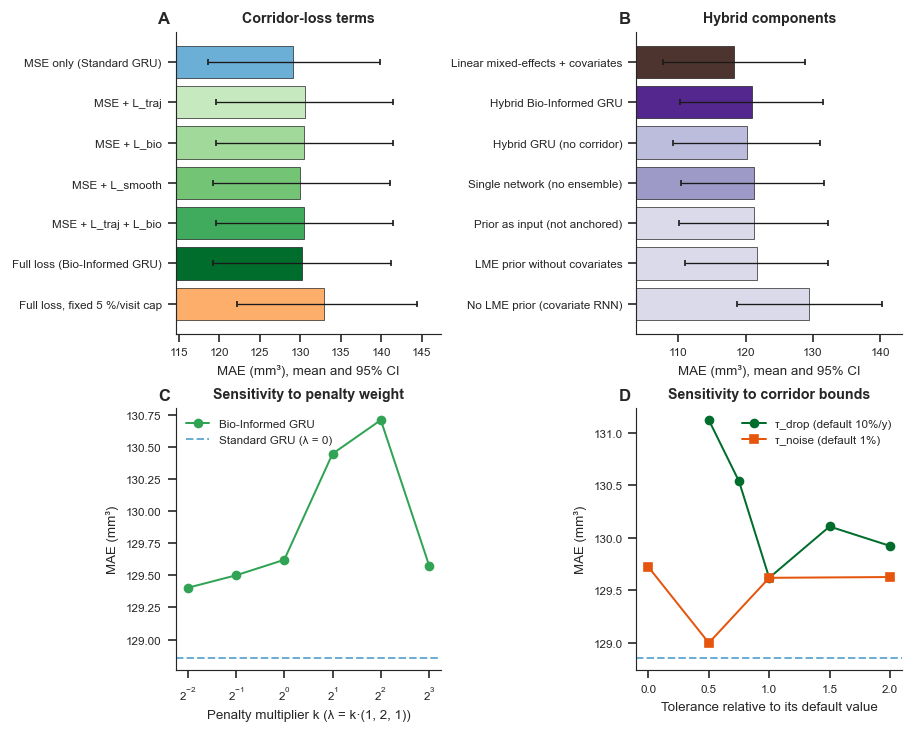

In [24]:
# Manuscript Fig 5: ablations and sensitivity
fig = plt.figure(figsize=(FIG_W, 6.0))
gsp = GridSpec(2, 2, figure=fig, height_ratios=[1.15, 1])
def hbar(ax, T, order, cols, title):
    A = T.set_index('Model').reindex(order); ys = np.arange(len(A))[::-1]
    ax.barh(ys, A['MAE mean'], xerr=[A['MAE mean'] - A['MAE 95% CI low'], A['MAE 95% CI high'] - A['MAE mean']], color=cols,
            edgecolor='k', lw=0.4, error_kw={'lw': 0.8, 'capsize': 2})
    ax.set_yticks(ys); ax.set_yticklabels(A.index); ax.set_xlim(A['MAE 95% CI low'].min() - 4, A['MAE 95% CI high'].max() + 3)
    ax.set_xlabel('MAE (mm³), mean and 95% CI'); ax.set_title(title)
ax = fig.add_subplot(gsp[0, 0]); panel(ax, 'A')
hbar(ax, SA, ABL_ORDER, ['#6BAED6', '#C7E9C0', '#A1D99B', '#74C476', '#41AB5D', '#006D2C', '#FDAE6B'], 'Corridor-loss terms')
ax = fig.add_subplot(gsp[0, 1]); panel(ax, 'B')
hbar(ax, SH, HABL_ORDER, [PALETTE['Linear mixed-effects + covariates'], PALETTE[PROPOSED], '#BCBDDC', '#9E9AC8', '#DADAEB', '#DADAEB', '#DADAEB'],
     'Hybrid components')
Ssens = SS.set_index('Model')
ax = fig.add_subplot(gsp[1, 0]); panel(ax, 'C')
ks = [0.25, 0.5, 1, 2, 4, 8]
ax.plot(ks, [Ssens.loc[f'λ×{k}', 'MAE mean'] if k != 1 else Ssens.loc[DEF, 'MAE mean'] for k in ks], 'o-', color='#31A354', label='Bio-Informed GRU')
std_r0 = per_repeat(P_all, 'T1').query("model == 'Standard GRU' and repeat == 0").MAE.iloc[0]
ax.axhline(std_r0, color='#6BAED6', ls='--', label='Standard GRU (λ = 0)')
ax.set_xscale('log', base=2); ax.set_xlabel('Penalty multiplier k (λ = k·(1, 2, 1))'); ax.set_ylabel('MAE (mm³)')
ax.set_title('Sensitivity to penalty weight'); ax.legend(frameon=False)
ax = fig.add_subplot(gsp[1, 1]); panel(ax, 'D')
tds = [0.05, 0.075, 0.10, 0.15, 0.20]; tns = [0.0, 0.005, 0.01, 0.02]
ax.plot([td / 0.10 for td in tds], [Ssens.loc[f'τ_drop={td:g}/y', 'MAE mean'] if td != 0.10 else Ssens.loc[DEF, 'MAE mean'] for td in tds], 'o-', color='#006D2C', label='τ_drop (default 10%/y)')
ax.plot([tn / 0.01 for tn in tns], [Ssens.loc[f'τ_noise={tn:g}', 'MAE mean'] if tn != 0.01 else Ssens.loc[DEF, 'MAE mean'] for tn in tns], 's-', color='#E6550D', label='τ_noise (default 1%)')
ax.axhline(std_r0, color='#6BAED6', ls='--'); ax.set_xlabel('Tolerance relative to its default value'); ax.set_ylabel('MAE (mm³)')
ax.set_title('Sensitivity to corridor bounds'); ax.legend(frameon=False)
savefig(fig, 'Fig5_ablation_sensitivity', plos='Fig5')

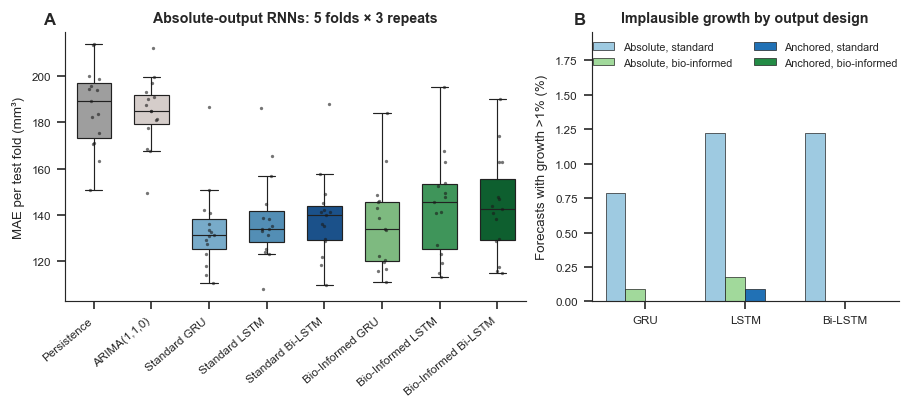

In [25]:
# Manuscript Fig 6: output parameterisation (absolute vs anchored) and fold-to-fold variability
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.3), gridspec_kw={'width_ratios': [1.5, 1]})
ax = axes[0]; panel(ax, 'A')
order = ['Persistence', 'ARIMA(1,1,0)'] + [s['name'] for s in PAPER_SPECS]
sns.boxplot(data=fold_mae, x='model', y='ae', order=order, palette=PALETTE, ax=ax, width=0.6, fliersize=0, linewidth=0.7)
sns.stripplot(data=fold_mae, x='model', y='ae', order=order, color='k', size=2, alpha=0.6, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('MAE per test fold (mm³)'); ax.tick_params(axis='x', rotation=40)
for lab in ax.get_xticklabels(): lab.set_ha('right')
ax.set_title(f'Absolute-output RNNs: {CFG["n_folds"]} folds × {CFG["n_repeats"]} repeats')
ax = axes[1]; panel(ax, 'B')
names = ['GRU', 'LSTM', 'Bi-LSTM']; x = np.arange(3); w = 0.2
SPi = SP.set_index('Model'); S1i = S1.set_index('Model')
for j, (lab, src, pre, c) in enumerate([('Absolute, standard', SPi, 'Standard', '#9ECAE1'), ('Absolute, bio-informed', SPi, 'Bio-Informed', '#A1D99B'),
                                        ('Anchored, standard', S1i, 'Standard', '#2171B5'), ('Anchored, bio-informed', S1i, 'Bio-Informed', '#238B45')]):
    ax.bar(x + (j - 1.5) * w, [src.loc[f'{pre} {n}', 'Growth violation (%)'] for n in names], w, color=c, edgecolor='k', lw=0.4, label=lab)
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylabel('Forecasts with growth >1% (%)'); ax.set_title('Implausible growth by output design')
ax.set_ylim(0, max(SPi.loc[[f'Standard {n}' for n in names], 'Growth violation (%)'].max() * 1.6, 0.5)); ax.legend(frameon=False, ncol=2, loc='upper center', fontsize=6.5)
savefig(fig, 'Fig6_output_parameterisation', plos='Fig6')

In [26]:
# Manuscript Fig 8: prediction intervals (calibration + examples)
fig = plt.figure(figsize=(FIG_W, 5.4))
gsp = GridSpec(2, 4, figure=fig, height_ratios=[1, 1.05])
ax = fig.add_subplot(gsp[0, :2]); panel(ax, 'A')
mcols = {'Hybrid (conformal)': PALETTE[PROPOSED], 'LME + cov. (conformal)': '#8D6E63', 'LME + cov. (analytic)': '#4E342E'}
for mname, g in COV.groupby('method'):
    ax.plot(100 * g.level, g['coverage (%)'], 'o-', color=mcols[mname], label=mname, ms=4)
ax.plot([45, 100], [45, 100], 'k--', lw=0.7); ax.set_xlabel('Nominal coverage (%)'); ax.set_ylabel('Empirical coverage (%)')
ax.set_title('Calibration of prediction intervals'); ax.legend(frameon=False)
ax = fig.add_subplot(gsp[0, 2:]); panel(ax, 'B')
for mname, g in COV.groupby('method'):
    ax.plot(100 * g.level, g['mean width (mm³)'], 'o-', color=mcols[mname], label=mname, ms=4)
ax.set_xlabel('Nominal coverage (%)'); ax.set_ylabel('Mean interval width (mm³)'); ax.set_title('Interval width')
IVr = IV[IV.repeat == 0]
obs = IVr.assign(pct=100 * (IVr.y - IVr.v_last) / IVr.v_last)
picks = [obs[obs.dx == d].sort_values('pct').iloc[len(obs[obs.dx == d]) // 2].sid for d in DX_ORDER] + [obs.sort_values('pct').iloc[-3].sid]
show = ['Persistence', 'Linear mixed-effects + covariates', 'Standard GRU', PROPOSED]
for i, sid in enumerate(picks):
    ax = fig.add_subplot(gsp[1, i])
    if i == 0: panel(ax, 'C')
    g = df[df.SubjectID == sid]; row = IVr[IVr.sid == sid].iloc[0]
    ax.plot(12 * g.t.iloc[:-1], g.Volume_mm3.iloc[:-1], 'ko-', lw=1.3, ms=3, label='Observed history')
    ax.errorbar(12 * g.t.iloc[-1] + 1.2, row.pred, yerr=[[row.pred - row.lo], [row.hi - row.pred]], fmt='none', ecolor=PALETTE[PROPOSED], capsize=2, lw=1, label='90% conformal PI')
    for m in show:
        p = P_all[(P_all.sid == sid) & (P_all.model == m) & P_all.final & (P_all.repeat == 0)].pred.iloc[0]
        ax.plot([12 * g.t.iloc[-2], 12 * g.t.iloc[-1]], [g.Volume_mm3.iloc[-2], p], '--', marker='o', ms=2.5, lw=0.9, color=PALETTE[m], label=m)
    ax.plot(12 * g.t.iloc[-1], g.Volume_mm3.iloc[-1], marker='*', color='gold', mec='k', mew=0.5, ms=10, ls='none', label='Observed target')
    ax.set_title(f'{sid} ({g.Diagnosis.iloc[0]})', fontsize=7.5); ax.set_xlabel('Months')
    if i == 0: ax.set_ylabel('Volume (mm³)')
h, l = ax.get_legend_handles_labels()
fig.legend(h, l, loc='outside lower center', ncol=4, frameon=False)
savefig(fig, 'Fig8_prediction_intervals', plos='Fig8')

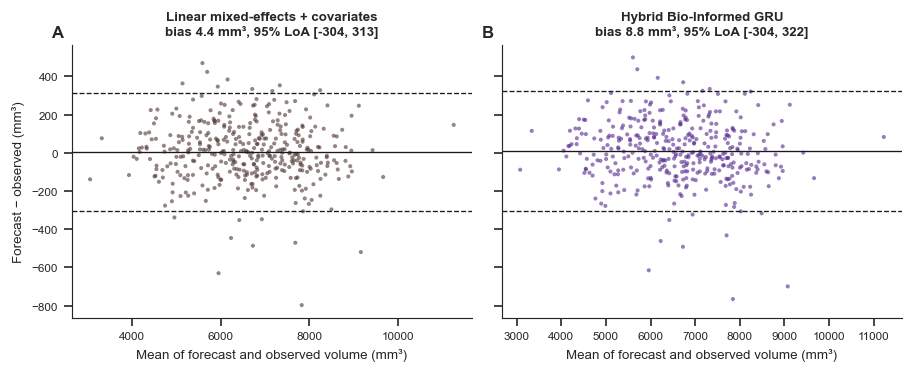

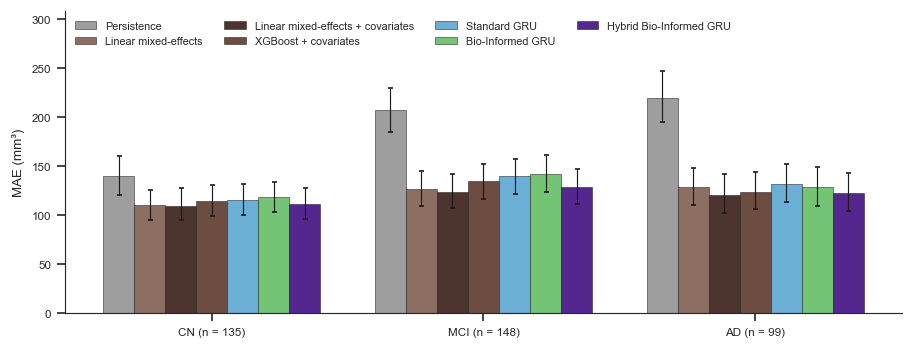

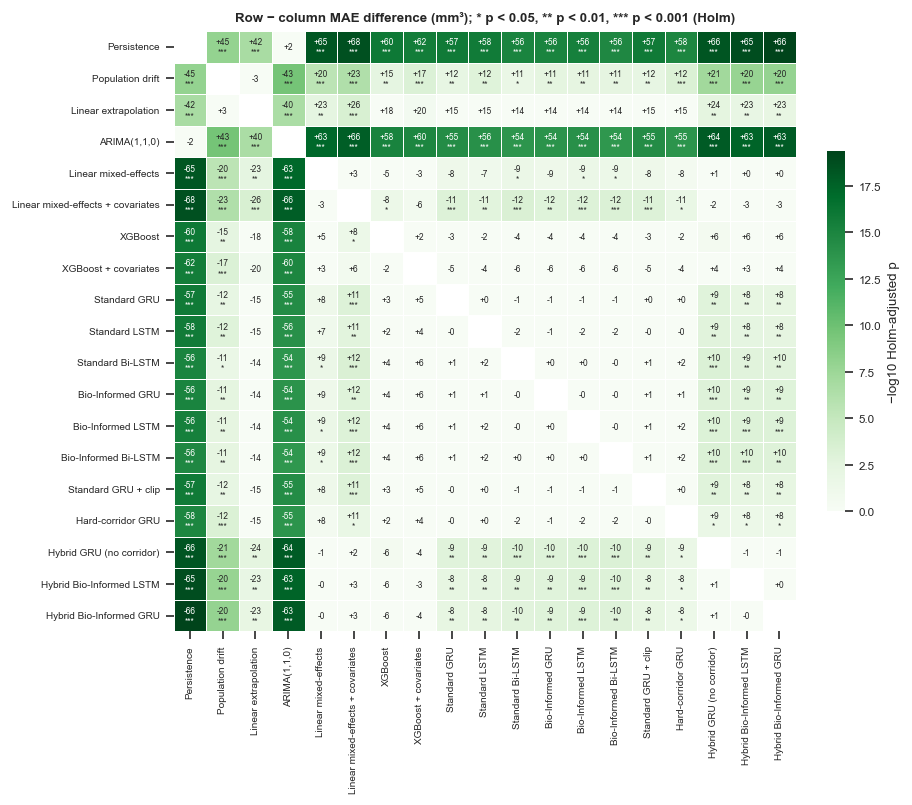

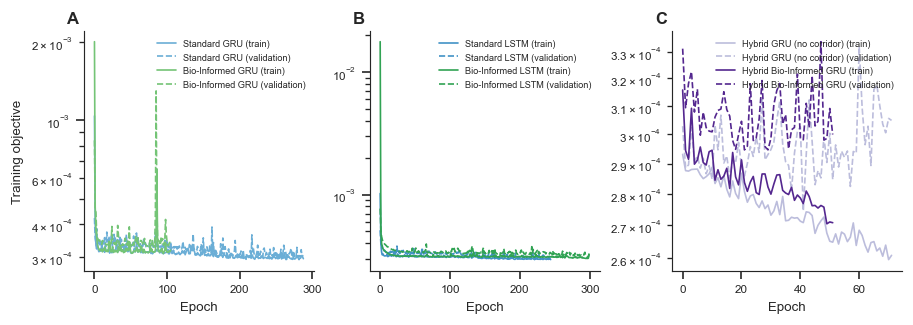

In [27]:
# Supporting figures: S1 Bland-Altman, S2 MAE by diagnosis, S3 pairwise significance, S4 learning curves
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.0), sharey=True)
for ax, m, L in zip(axes, ['Linear mixed-effects + covariates', PROPOSED], 'AB'):
    x = P_all[P_all.final & (P_all.model == m)].groupby('sid')[['y', 'pred']].mean()
    mean_, diff = (x.y + x.pred) / 2, x.pred - x.y; b, sd = diff.mean(), diff.std(ddof=1)
    ax.scatter(mean_, diff, s=6, alpha=0.6, color=PALETTE[m], edgecolor='none')
    for v, ls in [(b, '-'), (b - 1.96 * sd, '--'), (b + 1.96 * sd, '--')]: ax.axhline(v, color='k', ls=ls, lw=0.8)
    ax.set_title(f'{m}\nbias {b:.1f} mm³, 95% LoA [{b - 1.96 * sd:.0f}, {b + 1.96 * sd:.0f}]', fontsize=8)
    ax.set_xlabel('Mean of forecast and observed volume (mm³)'); panel(ax, L)
axes[0].set_ylabel('Forecast − observed (mm³)')
savefig(fig, 'FigS1_bland_altman', plos='S1_Fig')

pd_rows = []
for m in MODEL_ORDER:
    for dx in DX_ORDER:
        x = P_all[P_all.final & (P_all.model == m) & (P_all.dx == dx)]
        ae = x.assign(ae=(x.pred - x.y).abs()).groupby('sid').ae.mean().to_numpy(); ci = boot_ci(ae)
        pd_rows.append({'Model': m, 'DX': dx, 'MAE': ae.mean(), 'CI low': ci[0], 'CI high': ci[1], 'n': len(ae)})
PDX = pd.DataFrame(pd_rows); save_table(PDX.round(2), 'Table_S6_MAE_by_diagnosis')
sel = ['Persistence', 'Linear mixed-effects', 'Linear mixed-effects + covariates', 'XGBoost + covariates', 'Standard GRU', 'Bio-Informed GRU', PROPOSED]
fig, ax = plt.subplots(figsize=(FIG_W, 2.8)); w = 0.8 / len(sel)
for i, m in enumerate(sel):
    x = PDX[PDX.Model == m].set_index('DX').reindex(DX_ORDER); xs = np.arange(3) + (i - len(sel) / 2 + 0.5) * w
    ax.bar(xs, x.MAE, w, yerr=[x.MAE - x['CI low'], x['CI high'] - x.MAE], color=PALETTE[m], edgecolor='k', lw=0.3, capsize=1.5, label=m, error_kw={'lw': 0.7})
ax.set_xticks(range(3)); ax.set_xticklabels([f'{d} (n = {int(subj.DX.eq(d).sum())})' for d in DX_ORDER]); ax.set_ylabel('MAE (mm³)')
ax.legend(ncol=4, frameon=False, loc='upper left', fontsize=6.5); ax.set_ylim(0, PDX[PDX.Model.isin(sel)]['CI high'].max() * 1.25)
savefig(fig, 'FigS2_MAE_by_diagnosis', plos='S2_Fig')

ms_ = [m for m in MODEL_ORDER if m in SE1.columns]
pm = pd.DataFrame(np.nan, index=ms_, columns=ms_); dm = pm.copy()
pairs = [(a, b) for i, a in enumerate(ms_) for b in ms_[i + 1:]]
raw = [stats.wilcoxon(SE1[a] - SE1[b]).pvalue if np.any(SE1[a] != SE1[b]) else 1.0 for a, b in pairs]
for (a, b), p in zip(pairs, multipletests(raw, method='holm')[1]):
    pm.loc[a, b] = pm.loc[b, a] = p; dm.loc[a, b] = SE1[a].mean() - SE1[b].mean(); dm.loc[b, a] = -dm.loc[a, b]
annot = dm.map(lambda v: '' if np.isnan(v) else f'{v:+.0f}') + pm.map(lambda p: '' if np.isnan(p) else ('\n***' if p < 1e-3 else '\n**' if p < 1e-2 else '\n*' if p < 0.05 else ''))
fig, ax = plt.subplots(figsize=(FIG_W, 6.6))
sns.heatmap(-np.log10(pm.astype(float)), annot=annot, fmt='', cmap='Greens', cbar_kws={'label': '−log10 Holm-adjusted p', 'shrink': 0.6},
            linewidths=0.4, linecolor='white', annot_kws={'fontsize': 5}, ax=ax)
ax.set_title('Row − column MAE difference (mm³); * p < 0.05, ** p < 0.01, *** p < 0.001 (Holm)', fontsize=8)
ax.tick_params(labelsize=6)
savefig(fig, 'FigS3_pairwise_significance', plos='S3_Fig')

curv = {m['model']: m['curves'] for m in R_main['meta'] if m['repeat'] == 0 and m['fold'] == 0}
hcurv = {m['model']: m['curves'] for m in R_hyb['meta'] if m['repeat'] == 0 and m['fold'] == 0 and m.get('ens', 0) == 0}
fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 2.6))
for ax, pair, L in zip(axes, [('Standard GRU', 'Bio-Informed GRU'), ('Standard LSTM', 'Bio-Informed LSTM'), ('Hybrid GRU (no corridor)', PROPOSED)], 'ABC'):
    for m in pair:
        cv = curv.get(m) or hcurv.get(m)
        ax.plot(cv['train'], color=PALETTE[m], lw=1, label=f'{m} (train)'); ax.plot(cv['val'], color=PALETTE[m], lw=1, ls='--', label=f'{m} (validation)')
    ax.set_yscale('log'); ax.set_xlabel('Epoch'); ax.legend(frameon=False, fontsize=5.5); panel(ax, L)
axes[0].set_ylabel('Training objective')
savefig(fig, 'FigS4_learning_curves', plos='S4_Fig')

## 13. Export summary numbers

In [28]:
S1i, S2i, SPi = S1.set_index('Model'), S2.set_index('Model'), SP.set_index('Model')
paper = {
    'config': CFG, 'environment': ENV, 'noise': NOISE, 'n_subjects': int(len(subj)), 'n_scans': int(len(df)),
    'n_windows_T2': int(len(W)), 'dx_counts': subj.DX.value_counts().to_dict(),
    'T1_horizon_mean': float(W[W.final].dt.mean()), 'T1_horizon_sd': float(W[W.final].dt.std()),
    'groundtruth': gt_corr.to_dict('index'), 'arima_fallback_T2': int(B['arima_fail'].sum()),
    'T1': S1i.round(4).to_dict('index'), 'T2': S2i.round(4).to_dict('index'),
    'tests': CMP.round(6).to_dict('records'), 'equivalence': EQ.round(6).to_dict('records'), 'violation_diff': VIOL.to_dict('records'),
    'coverage': COV.to_dict('records'), 'corridor_ablation': ABL.to_dict('records'), 'hybrid_ablation': HABL.to_dict('records'),
    'sensitivity': SENS.to_dict('records'), 'absolute_protocol': SPT.round(4).set_index('Model').to_dict('index'),
    'absolute_protocol_tests': CP.round(6).to_dict('records'), 'by_dx': PDX.round(3).to_dict('records'),
    'lme_cov_fixed_effects': _lme.res.fe_params.round(5).to_dict(),
    'best_epochs': pd.DataFrame(R_main['meta'] + R_hyb['meta']).groupby('model').best_epoch.median().to_dict()}
json.dump(paper, open(OUT / 'paper_numbers.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

lines = ['# Key results', '', f"Cohort: {len(subj)} subjects, {len(df)} scans. T1 = final-scan forecast (horizon {W[W.final].dt.mean():.2f} y).", '']
for m in MODEL_ORDER:
    r = S1i.loc[m]
    lines.append(f"- {m}: MAE {r['MAE mean']:.1f} ± {r['MAE sd']:.1f} [{r['MAE 95% CI low']:.1f}, {r['MAE 95% CI high']:.1f}]; skill {r['Skill vs persistence (%)']:.1f}%; "
                 f"r(change) {r['r (change)']:.3f}; growth viol. {r['Growth violation (%)']:.2f}%")
lines += ['', '## Planned comparisons (Holm)'] + [f"- {c['A']} vs {c['B']}: ΔMAE {c['ΔMAE (A−B)']:+.1f} [{c['CI low']:.1f}, {c['CI high']:.1f}], p_Holm = {c['p (Holm)']:.3g}" for _, c in CMP.iterrows()]
lines += ['', '## Equivalence (TOST, ±5 mm³)'] + [f"- {e['A']} vs {e['B']}: ΔMAE {e['ΔMAE']:+.2f}, 90% CI [{e['90% CI low']:.2f}, {e['90% CI high']:.2f}], p = {e['p (TOST)']:.3g}, equivalent = {e['equivalent']}" for _, e in EQ.iterrows()]
(OUT / 'RESULTS_SUMMARY.md').write_text('\n'.join(lines)); print('\n'.join(lines))

from joblib.externals.loky import get_reusable_executor
get_reusable_executor().shutdown(wait=True)

# Key results

Cohort: 382 subjects, 1957 scans. T1 = final-scan forecast (horizon 1.01 y).

- Persistence: MAE 186.5 ± 0.0 [172.3, 201.0]; skill 0.0%; r(change) nan; growth viol. 0.00%
- Population drift: MAE 141.2 ± 0.2 [130.2, 152.5]; skill 24.3%; r(change) -0.183; growth viol. 0.00%
- Linear extrapolation: MAE 144.2 ± 0.0 [130.8, 157.9]; skill 22.7%; r(change) 0.216; growth viol. 3.14%
- ARIMA(1,1,0): MAE 184.4 ± 0.0 [171.4, 198.2]; skill 1.1%; r(change) 0.182; growth viol. 12.30%
- Linear mixed-effects: MAE 121.4 ± 1.7 [110.6, 132.1]; skill 34.9%; r(change) 0.368; growth viol. 0.17%
- Linear mixed-effects + covariates: MAE 118.2 ± 0.9 [107.8, 128.8]; skill 36.6%; r(change) 0.391; growth viol. 0.09%
- XGBoost: MAE 126.6 ± 1.7 [116.2, 137.3]; skill 32.1%; r(change) 0.302; growth viol. 0.26%
- XGBoost + covariates: MAE 124.5 ± 2.5 [114.4, 135.1]; skill 33.2%; r(change) 0.325; growth viol. 0.09%
- Standard GRU: MAE 129.1 ± 0.3 [118.6, 139.9]; skill 30.8%; r(change) 0.239; growth viol.